In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df_books = pd.read_csv(r"C:\Users\CHIRIKI MANOJ KUMAR\EDA\New_Datasets\Book_recommend1\Books.csv")

C:\Users\CHIRIKI MANOJ KUMAR\AppData\Local\Temp\ipykernel_24612\3129278195.py:1: DtypeWarning: Columns (0: Year-Of-Publication) have mixed types. Specify dtype option on import or set low_memory=False.
  df_books = pd.read_csv(r"C:\Users\CHIRIKI MANOJ KUMAR\EDA\New_Datasets\Book_recommend1\Books.csv")


# **1 . BOOKS DATASET**

In [4]:
print("Books shape -",df_books.shape)

Books shape - (271360, 8)


In [5]:
df_books.head()

,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999,W. W. Norton &amp; Company,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...


In [6]:
df_books.columns

Index(['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Publisher',
       'Image-URL-S', 'Image-URL-M', 'Image-URL-L'],
      dtype='str')

In [7]:
df_books.info()

<class 'pandas.DataFrame'>
RangeIndex: 271360 entries, 0 to 271359
Data columns (total 8 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   ISBN                 271360 non-null  str   
 1   Book-Title           271360 non-null  str   
 2   Book-Author          271358 non-null  str   
 3   Year-Of-Publication  271360 non-null  object
 4   Publisher            271358 non-null  str   
 5   Image-URL-S          271360 non-null  str   
 6   Image-URL-M          271360 non-null  str   
 7   Image-URL-L          271357 non-null  str   
dtypes: object(1), str(7)
memory usage: 83.4+ MB


#### ->Here Year Of Publication Column only have object datattype which is weird because it has the data of year and it should be either int or float .

In [8]:
df_books.isnull().sum()

ISBN                   0
Book-Title             0
Book-Author            2
Year-Of-Publication    0
Publisher              2
Image-URL-S            0
Image-URL-M            0
Image-URL-L            3
dtype: int64

In [9]:
df_books[df_books.isnull().any(axis=1)]

,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
118033,0751352497,A+ Quiz Masters:01 Earth,NaN,1999,Dorling Kindersley,http://images.amazon.com/images/P/0751352497.0...,http://images.amazon.com/images/P/0751352497.0...,http://images.amazon.com/images/P/0751352497.0...
128890,193169656X,Tyrant Moon,Elaine Corvidae,2002,NaN,http://images.amazon.com/images/P/193169656X.0...,http://images.amazon.com/images/P/193169656X.0...,http://images.amazon.com/images/P/193169656X.0...
129037,1931696993,Finders Keepers,Linnea Sinclair,2001,NaN,http://images.amazon.com/images/P/1931696993.0...,http://images.amazon.com/images/P/1931696993.0...,http://images.amazon.com/images/P/1931696993.0...
187689,9627982032,The Credit Suisse Guide to Managing Your Perso...,NaN,1995,Edinburgh Financial Publishing,http://images.amazon.com/images/P/9627982032.0...,http://images.amazon.com/images/P/9627982032.0...,http://images.amazon.com/images/P/9627982032.0...
209538,078946697X,"DK Readers: Creating the X-Men, How It All Beg...",2000,DK Publishing Inc,http://images.amazon.com/images/P/078946697X.0...,http://images.amazon.com/images/P/078946697X.0...,http://images.amazon.com/images/P/078946697X.0...,NaN
220731,2070426769,"Peuple du ciel, suivi de 'Les Bergers\"";Jean-M...",2003,Gallimard,http://images.amazon.com/images/P/2070426769.0...,http://images.amazon.com/images/P/2070426769.0...,http://images.amazon.com/images/P/2070426769.0...,NaN
221678,0789466953,"DK Readers: Creating the X-Men, How Comic Book...",2000,DK Publishing Inc,http://images.amazon.com/images/P/0789466953.0...,http://images.amazon.com/images/P/0789466953.0...,http://images.amazon.com/images/P/0789466953.0...,NaN


In [10]:
df_books['Year-Of-Publication'].value_counts().head(20)

Year-Of-Publication
2002    13903
2001    13715
1999    13414
2000    13373
1998    12116
2003    11610
1997    11494
1996    10687
1995    10259
1994     8857
1993     7920
1992     7390
1991     6926
1990     6394
1989     5825
1988     5545
1987     4761
2004     4629
1986     4258
1999     4017
Name: count, dtype: int64

In [11]:
year = pd.to_numeric(
    df_books['Year-Of-Publication'],
    errors='coerce'
)
df_books.loc[year.isna(),'Year-Of-Publication'].value_counts(
    dropna=False
)

Year-Of-Publication
DK Publishing Inc    2
Gallimard            1
Name: count, dtype: int64

#### -> That means we have 3 records which doesn't have numeric in their year row

In [12]:
year.describe()

count    271357.000000
mean       1959.760817
std         257.994226
min           0.000000
25%        1989.000000
50%        1995.000000
75%        2000.000000
max        2050.000000
Name: Year-Of-Publication, dtype: float64

#### -> The minimum year is 0 and the maximum is 2050. These values deserve investigation because 0 is not a normal publication year, and 2050 is a future year relative to the dataset's historical context.

In [13]:
year[(year==0) | (year > 2026)].value_counts().sort_index()

Year-Of-Publication
0.0       4618
2030.0       7
2037.0       1
2038.0       1
2050.0       2
Name: count, dtype: int64

#### -> It has 4618 rows 0 as publication year which is enough to not treat it as a Ordinary publication year .
#### -> And we have 11 records which are greater publication year than 2026.

In [14]:
df_books.loc[
    (year==0) | (year>2026),
    ['ISBN','Book-Title','Book-Author','Year-Of-Publication','Publisher']   
].head(15)

,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher
176,3150000335,Kabale Und Liebe,Schiller,0,"Philipp Reclam, Jun Verlag GmbH"
188,342311360X,Die Liebe in Den Zelten,Gabriel Garcia Marquez,0,Deutscher Taschenbuch Verlag (DTV)
288,0571197639,Poisonwood Bible Edition Uk,Barbara Kingsolver,0,Faber Faber Inc
351,3596214629,"Herr Der Fliegen (Fiction, Poetry and Drama)",Golding,0,Fischer Taschenbuch Verlag GmbH
542,8845229041,Biblioteca Universale Rizzoli: Sulla Sponda De...,P Coelho,0,Fabbri - RCS Libri
641,0345251733,Rainbow the Stormy Life of Judy Garland,Christopher Finch,0,Ballantine Books
646,0590021117,Little House On the Prairie,Laura Ingall Wilder,0,Scholastic Inc
728,2070362388,Ravage,Rene Barjavel,0,Gallimard French
732,2266033689,Le Diable Au Corps,Raymond Radiguet,0,Presses Pocket French
735,2070334368,La Guerre Des Boutons,Pergaud,0,Livre de Poche


#### -> That means even though they dont have year but still have useful content .
#### -> So we cant remove all those rows .
#### -> And from previous observations we found out that three records contain Book Author's names in their year content .

In [15]:
df_books.loc[
    year.isna(),
    ['ISBN','Book-Title','Book-Author','Year-Of-Publication','Publisher']
]


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher
209538,078946697X,"DK Readers: Creating the X-Men, How It All Beg...",2000,DK Publishing Inc,http://images.amazon.com/images/P/078946697X.0...
220731,2070426769,"Peuple du ciel, suivi de 'Les Bergers\"";Jean-M...",2003,Gallimard,http://images.amazon.com/images/P/2070426769.0...
221678,0789466953,"DK Readers: Creating the X-Men, How Comic Book...",2000,DK Publishing Inc,http://images.amazon.com/images/P/0789466953.0...


In [16]:
df_books.duplicated().sum()

np.int64(0)

#### -> This Dataset have no Duplicates

## Year-Of-Publication Column Handling

In [17]:
df_books['Year-Clean'] = pd.to_numeric(
    df_books['Year-Of-Publication'],
    errors='coerce'
)

#### -> Created a column named Year-Clean of numeric datatype without removing old column.
#### -> And the Columns which can't Convert will be stored as null values(NaN)

In [18]:
df_books['Year-Clean'].isnull().sum()

np.int64(3)

In [19]:
df_books.loc[
    (df_books['Year-Clean'] == 0) | (df_books['Year-Clean'] > 2026),
    'Year-Clean'
] = float('nan')

In [20]:
df_books['Year-Clean'].isnull().sum()

np.int64(4632)

#### -> Converted all those years which are equal to 0 and greater than 2026 to null because all of them are incorrect values .

## The null values in this particular dataset will be remained as null because we cant replace them with mean or median or any random value or text because these are very important columns such as names of publishers and authors and the publication years .

# 1 . Year of Publication column handled

In [21]:
df_books['ISBN'].duplicated().sum()

np.int64(0)

# 2 . ISBN Column has no duplicate values

In [22]:
df_books.isnull().sum()

ISBN                      0
Book-Title                0
Book-Author               2
Year-Of-Publication       0
Publisher                 2
Image-URL-S               0
Image-URL-M               0
Image-URL-L               3
Year-Clean             4632
dtype: int64

In [23]:
df_books[df_books.isnull().any(axis=1)]

,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L,Year-Clean
176,3150000335,Kabale Und Liebe,Schiller,0,"Philipp Reclam, Jun Verlag GmbH",http://images.amazon.com/images/P/3150000335.0...,http://images.amazon.com/images/P/3150000335.0...,http://images.amazon.com/images/P/3150000335.0...,NaN
188,342311360X,Die Liebe in Den Zelten,Gabriel Garcia Marquez,0,Deutscher Taschenbuch Verlag (DTV),http://images.amazon.com/images/P/342311360X.0...,http://images.amazon.com/images/P/342311360X.0...,http://images.amazon.com/images/P/342311360X.0...,NaN
288,0571197639,Poisonwood Bible Edition Uk,Barbara Kingsolver,0,Faber Faber Inc,http://images.amazon.com/images/P/0571197639.0...,http://images.amazon.com/images/P/0571197639.0...,http://images.amazon.com/images/P/0571197639.0...,NaN
351,3596214629,"Herr Der Fliegen (Fiction, Poetry and Drama)",Golding,0,Fischer Taschenbuch Verlag GmbH,http://images.amazon.com/images/P/3596214629.0...,http://images.amazon.com/images/P/3596214629.0...,http://images.amazon.com/images/P/3596214629.0...,NaN
542,8845229041,Biblioteca Universale Rizzoli: Sulla Sponda De...,P Coelho,0,Fabbri - RCS Libri,http://images.amazon.com/images/P/8845229041.0...,http://images.amazon.com/images/P/8845229041.0...,http://images.amazon.com/images/P/8845229041.0...,NaN
...,...,...,...,...,...,...,...,...,...
270794,014029953X,Foe (Essential.penguin S.),J.M. Coetzee,0,Penguin Books Ltd,http://images.amazon.com/images/P/014029953X.0...,http://images.amazon.com/images/P/014029953X.0...,http://images.amazon.com/images/P/014029953X.0...,NaN
270913,0340571187,Postmens House,Maggie Hemingway,0,Trafalgar Square,http://images.amazon.com/images/P/0340571187.0...,http://images.amazon.com/images/P/0340571187.0...,http://images.amazon.com/images/P/0340571187.0...,NaN
271094,8427201079,El Misterio De Sittaford,Agatha Christie,0,Editorial Molino,http://images.amazon.com/images/P/8427201079.0...,http://images.amazon.com/images/P/8427201079.0...,http://images.amazon.com/images/P/8427201079.0...,NaN
271182,0887781721,Tom Penny,Tony German,0,P. Martin Associates,http://images.amazon.com/images/P/0887781721.0...,http://images.amazon.com/images/P/0887781721.0...,http://images.amazon.com/images/P/0887781721.0...,NaN


In [24]:
df_books[df_books[['Book-Author','Publisher','Image-URL-L']].isnull().any(axis=1)]

,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L,Year-Clean
118033,0751352497,A+ Quiz Masters:01 Earth,NaN,1999,Dorling Kindersley,http://images.amazon.com/images/P/0751352497.0...,http://images.amazon.com/images/P/0751352497.0...,http://images.amazon.com/images/P/0751352497.0...,1999.0
128890,193169656X,Tyrant Moon,Elaine Corvidae,2002,NaN,http://images.amazon.com/images/P/193169656X.0...,http://images.amazon.com/images/P/193169656X.0...,http://images.amazon.com/images/P/193169656X.0...,2002.0
129037,1931696993,Finders Keepers,Linnea Sinclair,2001,NaN,http://images.amazon.com/images/P/1931696993.0...,http://images.amazon.com/images/P/1931696993.0...,http://images.amazon.com/images/P/1931696993.0...,2001.0
187689,9627982032,The Credit Suisse Guide to Managing Your Perso...,NaN,1995,Edinburgh Financial Publishing,http://images.amazon.com/images/P/9627982032.0...,http://images.amazon.com/images/P/9627982032.0...,http://images.amazon.com/images/P/9627982032.0...,1995.0
209538,078946697X,"DK Readers: Creating the X-Men, How It All Beg...",2000,DK Publishing Inc,http://images.amazon.com/images/P/078946697X.0...,http://images.amazon.com/images/P/078946697X.0...,http://images.amazon.com/images/P/078946697X.0...,NaN,NaN
220731,2070426769,"Peuple du ciel, suivi de 'Les Bergers\"";Jean-M...",2003,Gallimard,http://images.amazon.com/images/P/2070426769.0...,http://images.amazon.com/images/P/2070426769.0...,http://images.amazon.com/images/P/2070426769.0...,NaN,NaN
221678,0789466953,"DK Readers: Creating the X-Men, How Comic Book...",2000,DK Publishing Inc,http://images.amazon.com/images/P/0789466953.0...,http://images.amazon.com/images/P/0789466953.0...,http://images.amazon.com/images/P/0789466953.0...,NaN,NaN


## 3 ) Handling Book-Title ,Book-Author and Publisher Columns

In [25]:
df_books[['Book-Title','Book-Author','Publisher']].head()

,Book-Title,Book-Author,Publisher
0,Classical Mythology,Mark P. O. Morford,Oxford University Press
1,Clara Callan,Richard Bruce Wright,HarperFlamingo Canada
2,Decision in Normandy,Carlo D'Este,HarperPerennial
3,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,Farrar Straus Giroux
4,The Mummies of Urumchi,E. J. W. Barber,W. W. Norton &amp; Company


#### -> Publisher column contains HTML phrases instead of text such as &amp so we will investigate it .

In [26]:
df_books['Publisher'].str.contains(
    '&amp;',
    na=False
).sum()

np.int64(15791)

#### -> It contains 15791 html entities so this dataset may have text as html entities in other columns also so we are going to convert those into text.

In [27]:
df_books['Book-Author'].str.contains(
    '&amp;',
    na=False
).sum()

np.int64(270)

In [28]:
df_books['Book-Title'].str.contains(
    '&amp;',
    na=False
).sum()

np.int64(4870)

In [29]:
import html

In [30]:
df_books['Book-Author'] = df_books['Book-Author'].apply(
    lambda x:html.unescape(x) if isinstance(x,str) else x
)
df_books['Book-Title'] = df_books['Book-Title'].apply(
    lambda x:html.unescape(x) if isinstance(x,str) else x
)
df_books['Publisher'] = df_books['Publisher'].apply(
    lambda x:html.unescape(x) if isinstance(x,str) else x
)

#### -> We converted all the text which are in html format is converted into normal text.

In [31]:
df_books['Publisher'].str.contains(
    '&amp;',
    na=False
).sum()

np.int64(0)

In [32]:
df_books.head()

,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L,Year-Clean
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,2002.0
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,2001.0
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,1991.0
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,1999.0
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999,W. W. Norton & Company,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,1999.0


#### => Now We will check for whitespaces so that grouping and filtering can be easier .

In [33]:
text_columns = ['Book-Title','Book-Author','Publisher']
for column in text_columns:
    count = df_books[column].ne(
        df_books[column].str.strip()
    ).sum()
    
    print(f"{column}: {count}")


Book-Title: 47
Book-Author: 9
Publisher: 4


In [34]:
for column in text_columns:
    df_books[column] = df_books[column].str.strip()

In [35]:
text_columns = ['Book-Title','Book-Author','Publisher']
for column in text_columns:
    count = df_books[column].ne(
        df_books[column].str.strip()
    ).sum()
    
    print(f"{column}: {count}")


Book-Title: 0
Book-Author: 2
Publisher: 2


#### -> Removed all the white spaces in those 3 columns now there are 4 rows remained which still shows as they contains whitespaces.

In [36]:
for column in ['Book-Author', 'Publisher']:
    print(f"\n{column}")

    print(
        df_books.loc[
            df_books[column].ne(df_books[column].str.strip()),
            column
        ]
    )


Book-Author
118033    NaN
187689    NaN
Name: Book-Author, dtype: str

Publisher
128890    NaN
129037    NaN
Name: Publisher, dtype: str


#### -> Those remaining 4 values are null values.

In [37]:
df_books[['Book-Title', 'Book-Author', 'Publisher']].isnull().sum()

Book-Title     0
Book-Author    2
Publisher      2
dtype: int64

### 3.1 ) Checking for Duplicated Book Titles.

In [38]:
df_books['Book-Title'].duplicated().sum()


np.int64(29229)

#### --> So it have 29229 repeated book titles , it doesn't mean the row is duplicate , two books can have same title.

In [39]:
df_books.loc[
    df_books['Book-Title'].duplicated(keep=False),
    ['ISBN', 'Book-Title', 'Book-Author']
].head(10)

,ISBN,Book-Title,Book-Author
0,0195153448,Classical Mythology,Mark P. O. Morford
5,0399135782,The Kitchen God's Wife,Amy Tan
6,0425176428,What If?: The World's Foremost Military Histor...,Robert Cowley
9,074322678X,Where You'll Find Me: And Other Stories,Ann Beattie
13,1552041778,Jane Doe,R. J. Kaiser
14,1558746218,A Second Chicken Soup for the Woman's Soul (Ch...,Jack Canfield
18,0440234743,The Testament,John Grisham
27,0345402871,Airframe,Michael Crichton
28,0345417623,Timeline,MICHAEL CRICHTON
29,0684823802,OUT OF THE SILENT PLANET,C.S. Lewis


#### -> So the above results are the rows whose titles are repeated more than once including its first occurance.


In [40]:
df_books['Book-Title'].duplicated(keep=False).sum()

np.int64(49137)

In [41]:
df_books.loc[
    df_books['Book-Title'].duplicated(keep=False),
    ['Book-Title','ISBN','Book-Author','Publisher']
].head(10)

,Book-Title,ISBN,Book-Author,Publisher
0,Classical Mythology,0195153448,Mark P. O. Morford,Oxford University Press
5,The Kitchen God's Wife,0399135782,Amy Tan,Putnam Pub Group
6,What If?: The World's Foremost Military Histor...,0425176428,Robert Cowley,Berkley Publishing Group
9,Where You'll Find Me: And Other Stories,074322678X,Ann Beattie,Scribner
13,Jane Doe,1552041778,R. J. Kaiser,Mira Books
14,A Second Chicken Soup for the Woman's Soul (Ch...,1558746218,Jack Canfield,Health Communications
18,The Testament,0440234743,John Grisham,Dell
27,Airframe,0345402871,Michael Crichton,Ballantine Books
28,Timeline,0345417623,MICHAEL CRICHTON,Ballantine Books
29,OUT OF THE SILENT PLANET,0684823802,C.S. Lewis,Scribner


In [42]:
df_books['Book-Title'].nunique()

242131

In [43]:
df_books['Book-Title'].isna().sum()

np.int64(0)

In [44]:
title_counts = df_books['Book-Title'].value_counts()

title_counts.value_counts().sort_index()

count
1     222223
2      14944
3       2945
4       1069
5        432
6        220
7        115
8         70
9         39
10        24
11        13
12        12
13         8
14         1
15         3
16         3
17         1
18         2
19         1
20         3
21         1
24         1
27         1
Name: count, dtype: int64

#### -> The above result indicated how many unique titles have appeared how many times like 222223 titles appeared once.

In [45]:
df_books['Book-Title'].str.strip().eq('').sum()

np.int64(0)

## 3.2 ) All the Book Titles don't need to be Unique , Multiple book names can have same names 
### -> Book-Title Column is Handled

In [46]:
df_books['Book-Author'].dropna().str.isupper().sum()

np.int64(5925)

#### -> So it has 5925 titles which are written entirely on Upper Case

In [47]:
df_books['Book-Author'].dropna().str.istitle().sum()

np.int64(254380)

In [48]:
df_books.loc[
    df_books['Book-Author'].str.isupper(),
    'Book-Author'
].drop_duplicates().head(10)

28           MICHAEL CRICHTON
30            ARTHUR PHILLIPS
38          LAURA HILLENBRAND
52               JOHN GRISHAM
61     SUZANNE FISHER STAPLES
78             PHILIP PULLMAN
80           MICHAEL ONDAATJE
88                 DAVID FRUM
105        LOUIS DE BERNIERES
117             IRIS JOHANSEN
Name: Book-Author, dtype: str

In [49]:
df_books.loc[
    df_books['Book-Author'].str.contains(
        'Michael Crichton',
        case=False,
        na=False
    ),
    'Book-Author'
].drop_duplicates()

27    Michael Crichton
28    MICHAEL CRICHTON
Name: Book-Author, dtype: str

#### -> This dataset has same authors in diffrent in two capitaliation formats.

In [50]:
df_books['Author-Clean'] = df_books['Book-Author'].str.title()

#### -> It will create new column which converts all the author names into single title format

In [51]:
df_books[
    ['Book-Author','Author-Clean']
].head(10)

,Book-Author,Author-Clean
0,Mark P. O. Morford,Mark P. O. Morford
1,Richard Bruce Wright,Richard Bruce Wright
2,Carlo D'Este,Carlo D'Este
3,Gina Bari Kolata,Gina Bari Kolata
4,E. J. W. Barber,E. J. W. Barber
5,Amy Tan,Amy Tan
6,Robert Cowley,Robert Cowley
7,Scott Turow,Scott Turow
8,David Cordingly,David Cordingly
9,Ann Beattie,Ann Beattie


In [52]:
df_books['Author-Clean'].dropna().str.isupper().sum()

np.int64(41)

#### -> It still have 41 values as upper case may be those titles contains numbers or punctuation..

In [53]:
df_books.loc[
    df_books['Author-Clean'].str.isupper(),
    'Author-Clean'
].head(20)

13933                       S
27835                       J
29758                       X
30125                   M. T.
47632     S/N 008-046-00146-4
55569                   K. C.
63975                       N
87014                    H.D.
102271                      X
117990              J\ \"J\""
136950                      N
140682             W.I.T.C.H.
140684             W.I.T.C.H.
140685             W.I.T.C.H.
140686             W.I.T.C.H.
140687              W.I.T.C.H
140688             W.I.T.C.H.
140689             W.I.T.C.H.
140690             W.I.T.C.H.
143569                     P3
Name: Author-Clean, dtype: str

In [54]:
df_books.loc[
    df_books['Author-Clean'].str.len() <= 2,
    ['Book-Author','Author-Clean']
].head(20)


,Book-Author,Author-Clean
13933,S,S
27835,J,J
28171,Ai,Ai
29758,X,X
63975,N,N
75343,Ed,Ed
102271,X,X
104544,Ty,Ty
108819,tk,Tk
116382,Na,Na


In [55]:
(df_books['Author-Clean'].str.len() <=2).sum()

np.int64(37)

In [56]:
df_books.loc[
    df_books['Author-Clean'].str.len() <=2,
    'Author-Clean'
].value_counts()

Author-Clean
X     7
Tk    6
Na    5
N     4
Ky    3
Bh    3
Ai    2
S     1
J     1
Ed    1
Ty    1
P3    1
F     1
M     1
Name: count, dtype: int64

In [57]:
df_books['Author-Clean'].duplicated().sum()

np.int64(172020)

In [58]:
(
    df_books['Book-Author'] != df_books['Author-Clean']
).sum()

np.int64(16977)

In [59]:
df_books.head()

,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L,Year-Clean,Author-Clean
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,2002.0,Mark P. O. Morford
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,2001.0,Richard Bruce Wright
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,1991.0,Carlo D'Este
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,1999.0,Gina Bari Kolata
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999,W. W. Norton & Company,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,1999.0,E. J. W. Barber


In [60]:
(df_books.duplicated(
    subset=['Book-Title', 'Book-Author'],
    keep=False
).value_counts())

False    235438
True      35922
Name: count, dtype: int64

In [61]:
(df_books.groupby(['Book-Title','Book-Author','Publisher','Year-Clean']).size().sort_values(ascending=False)).head(10)

Book-Title                                                       Book-Author         Publisher                     Year-Clean
Phonics Fun: Reading Program, Pack 4 (Clifford the Big Red Dog)  Francie Alexander   Scholastic                    2003.0        12
Mythology                                                        Edith Hamilton      Signet Book                   1982.0         5
Dinosaurs: A Celebration                                         Dan Abnett          Client Distribution Services  1992.0         4
Chobits (Chobits)                                                Clamp               TokyoPop                      2003.0         4
Pride and Prejudice                                              Jane Austen         Signet Book                   1961.0         4
Anthem                                                           Ayn Rand            Signet Book                   1961.0         4
On the Road                                                      Jack Kerouac     

In [62]:
df_books.duplicated(subset=['Book-Title','Book-Author','Publisher','Year-Clean']).sum()

np.int64(1343)

#### -> That means Multiple Rows have same authors and book titles

#### -> we were gonna remove rows which have duplicated values 

In [63]:
df_books.drop_duplicates(
    subset=['Book-Title','Book-Author','Publisher','Year-Clean'],
    keep='first',
    inplace=True
)

In [64]:
df_books.shape

(270017, 10)

In [65]:
(df_books.groupby(['Book-Author','Book-Title','Publisher']).size().sort_values(ascending=False)).head(10)

Book-Author       Book-Title                                                  Publisher               
Lawrence Sanders  The First Deadly Sin                                        Berkley Publishing Group    6
T. H. White       Once and Future King                                        Berkley Publishing Group    6
John Varley       Titan                                                       Berkley Publishing Group    5
J. R. R. Tolkien  The Two Towers (The Lord of the Rings, Part 2)              Houghton Mifflin Company    5
Frank Herbert     Dune                                                        Berkley Publishing Group    5
Dean R. Koontz    Whispers                                                    Berkley Publishing Group    5
Jude Deveraux     HIGHLAND VELVET                                             Pocket                      5
J. R. R. Tolkien  The Fellowship of the Ring (The Lord of the Rings, Part 1)  Houghton Mifflin Company    5
Lawrence Sanders  Second Deadly S

In [66]:
df_books.groupby(['Book-Title', 'Book-Author', 'Publisher']).size().gt(1).sum()

np.int64(3615)

In [67]:
df_books.duplicated(subset=['Book-Title','Book-Author','Publisher']).sum()

np.int64(3886)

#### -> Here there are 3615 distinct unique rows which are have duplicates of total 3886 rows 

In [68]:
def ordinal(n):
    suffix = 'th' if 10 <= n % 100 <= 20 else {1: 'st', 2: 'nd', 3: 'rd'}.get(n % 10, 'th')
    return f'{n}{suffix} Edition'


groups = ['Book-Title', 'Book-Author', 'Publisher']

counts = df_books.groupby(groups).size()
repeated = counts[counts > 1].index

mask = df_books.set_index(groups).index.isin(repeated)

df_books['Edition'] = None

valid_years = mask & df_books['Year-Clean'].notna()

ranks = (
    df_books.loc[valid_years]
    .groupby(groups)['Year-Clean']
    .rank(method='first')
    .astype(int)
    .map(ordinal)
)

df_books.loc[valid_years, 'Edition'] = ranks

In [69]:
df_books.columns

Index(['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Publisher',
       'Image-URL-S', 'Image-URL-M', 'Image-URL-L', 'Year-Clean',
       'Author-Clean', 'Edition'],
      dtype='str')

In [70]:
df_books.info()

<class 'pandas.DataFrame'>
Index: 270017 entries, 0 to 271359
Data columns (total 11 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ISBN                 270017 non-null  str    
 1   Book-Title           270017 non-null  str    
 2   Book-Author          270015 non-null  str    
 3   Year-Of-Publication  270017 non-null  object 
 4   Publisher            270015 non-null  str    
 5   Image-URL-S          270017 non-null  str    
 6   Image-URL-M          270017 non-null  str    
 7   Image-URL-L          270014 non-null  str    
 8   Year-Clean           265424 non-null  float64
 9   Author-Clean         270015 non-null  str    
 10  Edition              7451 non-null    object 
dtypes: float64(1), object(2), str(8)
memory usage: 94.9+ MB


In [71]:
df_books.isnull().sum()

ISBN                        0
Book-Title                  0
Book-Author                 2
Year-Of-Publication         0
Publisher                   2
Image-URL-S                 0
Image-URL-M                 0
Image-URL-L                 3
Year-Clean               4593
Author-Clean                2
Edition                262566
dtype: int64

In [72]:
df_books['Edition'].value_counts(dropna=False)

Edition
None           262566
1st Edition      3615
2nd Edition      3569
3rd Edition       211
4th Edition        43
5th Edition        11
6th Edition         2
Name: count, dtype: int64

In [73]:
df_books.isnull().sum()

ISBN                        0
Book-Title                  0
Book-Author                 2
Year-Of-Publication         0
Publisher                   2
Image-URL-S                 0
Image-URL-M                 0
Image-URL-L                 3
Year-Clean               4593
Author-Clean                2
Edition                262566
dtype: int64

In [74]:
display(df_books[df_books['Book-Author'].isna()])
display(df_books[df_books['Publisher'].isna()])

,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L,Year-Clean,Author-Clean,Edition
118033,0751352497,A+ Quiz Masters:01 Earth,NaN,1999,Dorling Kindersley,http://images.amazon.com/images/P/0751352497.0...,http://images.amazon.com/images/P/0751352497.0...,http://images.amazon.com/images/P/0751352497.0...,1999.0,NaN,None
187689,9627982032,The Credit Suisse Guide to Managing Your Perso...,NaN,1995,Edinburgh Financial Publishing,http://images.amazon.com/images/P/9627982032.0...,http://images.amazon.com/images/P/9627982032.0...,http://images.amazon.com/images/P/9627982032.0...,1995.0,NaN,None


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L,Year-Clean,Author-Clean,Edition
128890,193169656X,Tyrant Moon,Elaine Corvidae,2002,NaN,http://images.amazon.com/images/P/193169656X.0...,http://images.amazon.com/images/P/193169656X.0...,http://images.amazon.com/images/P/193169656X.0...,2002.0,Elaine Corvidae,None
129037,1931696993,Finders Keepers,Linnea Sinclair,2001,NaN,http://images.amazon.com/images/P/1931696993.0...,http://images.amazon.com/images/P/1931696993.0...,http://images.amazon.com/images/P/1931696993.0...,2001.0,Linnea Sinclair,None


In [75]:
df_books['Book-Features'] = (
    df_books['Book-Title'].fillna(' ') + ' - ' + df_books['Author-Clean'].fillna('')
)

In [76]:
df_books[['Book-Title','Author-Clean','Book-Features']].head()

,Book-Title,Author-Clean,Book-Features
0,Classical Mythology,Mark P. O. Morford,Classical Mythology - Mark P. O. Morford
1,Clara Callan,Richard Bruce Wright,Clara Callan - Richard Bruce Wright
2,Decision in Normandy,Carlo D'Este,Decision in Normandy - Carlo D'Este
3,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,Flu: The Story of the Great Influenza Pandemic...
4,The Mummies of Urumchi,E. J. W. Barber,The Mummies of Urumchi - E. J. W. Barber


### -> Created a new column which combines both Book-Title and Author 

## Data Cleaning and Handling — Books Dataset

The books dataset was inspected and cleaned to improve its consistency and prepare it for further analysis.

### Steps Performed

1. **Initial Data Inspection:** Examined the dataset's shape, columns, data types, and missing values.

2. **Publication Year Handling:** Created a `Year-Clean` column by converting publication years to numeric values. Invalid years, including non-numeric values, zero years, and years beyond 2026, were treated as missing values. The original `Year-Of-Publication` column was preserved.

3. **Duplicate Checking:** Checked for duplicate records and duplicate ISBNs. No duplicate ISBNs were found. Repeated titles and title-author-publisher combinations were examined separately because they may represent different editions.

4. **Text Cleaning:** Decoded HTML entities in book titles, author names, and publisher names using `html.unescape()`.

5. **Whitespace Removal:** Removed leading and trailing whitespace from the `Book-Title`, `Book-Author`, and `Publisher` columns.

6. **Author Normalization:** Created an `Author-Clean` column by standardizing author-name capitalization while preserving the original `Book-Author` column.

7. **Duplicate Book Handling:** Removed duplicate records based on the combination of `Book-Title`, `Book-Author`, `Publisher`, and `Year-Clean`, while retaining distinct publication years.

8. **Edition Identification:** Created an `Edition` column to label repeated title-author-publisher groups according to publication year, such as `1st Edition`, `2nd Edition`, and `3rd Edition`. Books occurring only once or having unavailable years were left without an edition label.

9. **Missing-Value Inspection:** Reviewed missing values in the cleaned dataset. Missing author, publisher, image URL, and publication-year values were retained rather than deleting potentially useful book records.

### Conclusion

The books dataset has undergone the main data-cleaning and handling steps. The original columns were preserved where appropriate, and additional cleaned columns were created for analysis. The dataset is now ready for the next stage of the project: cleaning and handling the ratings dataset.

# **2 . RATINGS DATASET**

In [77]:
df_ratings = pd.read_csv(r"C:\Users\CHIRIKI MANOJ KUMAR\EDA\New_Datasets\Book_recommend1\Ratings.csv")

In [78]:
df_ratings.head()

,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6


In [79]:
df_ratings.shape

(1149780, 3)

In [80]:
df_ratings.info()

<class 'pandas.DataFrame'>
RangeIndex: 1149780 entries, 0 to 1149779
Data columns (total 3 columns):
 #   Column       Non-Null Count    Dtype
---  ------       --------------    -----
 0   User-ID      1149780 non-null  int64
 1   ISBN         1149780 non-null  str  
 2   Book-Rating  1149780 non-null  int64
dtypes: int64(2), str(1)
memory usage: 37.3 MB


In [81]:
df_ratings['ISBN'].duplicated().sum()

np.int64(809224)

In [82]:
df_ratings['User-ID'].duplicated().sum()

np.int64(1044497)

In [83]:
df_ratings['Book-Rating'].duplicated().sum()

np.int64(1149769)

In [84]:
df_ratings.duplicated(subset=['User-ID','ISBN']).sum()

np.int64(0)

In [85]:
df_ratings['Book-Rating'].value_counts().sort_index()

Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64

In [86]:
df_ratings['User-ID'].nunique()

105283

## i ) First we are gonna remove the rows which were not present in books dataset by comparing ISBNs.

In [87]:
valid_isbn = df_books['ISBN'].unique()
ratings_unmatched = df_ratings[~df_ratings['ISBN'].isin(valid_isbn)]

In [88]:
ratings_unmatched.shape

(122892, 3)

In [89]:
ratings_unmatched['ISBN'].nunique()

71733

#### -> So there are 71733 Unique ISBN values which are not in the Books dataset.

In [90]:
df_ratings_clean = df_ratings[
    df_ratings['ISBN'].isin(df_books['ISBN'])
].copy()
df_ratings_clean.shape

(1026888, 3)

#### -> Created a DataFrame called df_ratings_clean and copied the information from ratings dataset which have the ISBN's present in Books DataSet

In [91]:
df_ratings_clean['Book-Rating'].value_counts().sort_index()

Book-Rating
0     644754
1       1476
2       2364
3       5105
4       7591
5      45183
6      31556
7      66132
8      91395
9      60475
10     70857
Name: count, dtype: int64

In [92]:
(
    df_ratings_clean['Book-Rating']
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

Book-Rating
0     62.79
1      0.14
2      0.23
3      0.50
4      0.74
5      4.40
6      3.07
7      6.44
8      8.90
9      5.89
10     6.90
Name: proportion, dtype: float64

In [93]:
df_ratings_clean.isnull().sum()

User-ID        0
ISBN           0
Book-Rating    0
dtype: int64

In [94]:
df_ratings_clean.duplicated().sum()

np.int64(0)

In [95]:
df_ratings_clean.info()

<class 'pandas.DataFrame'>
Index: 1026888 entries, 0 to 1149778
Data columns (total 3 columns):
 #   Column       Non-Null Count    Dtype
---  ------       --------------    -----
 0   User-ID      1026888 non-null  int64
 1   ISBN         1026888 non-null  str  
 2   Book-Rating  1026888 non-null  int64
dtypes: int64(2), str(1)
memory usage: 41.3 MB


#### -> We cannot perform any mathematical operations on User-ID and Book-Rating.
##### -> Because: 
##### -> i ) User-ID is numeric but Identifier 
##### ->ii ) Book-Rating are whole number and individual opinion
##### ->iii) ISBN is also an Identifier

## Data Cleaning and Handling — Ratings Dataset

The Ratings dataset was inspected to understand its structure, identify duplicate records, examine rating values, and check its relationship with the Books dataset.

### 1. Initial Dataset Inspection
- The original dataset contained 1,149,780 rows and 3 columns: `User-ID`, `ISBN`, and `Book-Rating`.
- The dataset was inspected using `head()`, `shape`, `info()`, and `isnull().sum()`.

### 2. Duplicate Record Check
- Duplicate records were checked using the combination of `User-ID` and `ISBN`.
- No duplicate user-book rating records were found.
- Each user had at most one rating record for a particular ISBN.

### 3. Rating Value Inspection
- The `Book-Rating` column contained values ranging from 0 to 10.
- A rating of 0 represents an interaction without an explicit rating.
- Ratings from 1 to 10 represent explicit ratings.
- The value 0 was retained because it is meaningful in the dataset and is not an invalid rating.

### 4. Matching Ratings with the Books Dataset
- The `ISBN` column was used to check the relationship between the Ratings and Books datasets.
- A total of 122,892 rating records contained ISBNs that were not present in the Books dataset.
- These records represented 71,733 distinct unmatched ISBNs.
- A cleaned DataFrame named `df_ratings_clean` was created by keeping only ratings whose ISBNs existed in `df_books`.
- The original `df_ratings` dataset was preserved.

### 5. Rating Distribution Analysis
- The frequency and percentage distribution of ratings were examined.
- Rating 0 accounted for approximately 62.79% of the cleaned dataset.
- Rating 8 was the most common explicit rating, accounting for approximately 8.90%.
- Rating 0 was retained because it represents an interaction without an explicit rating.

### 6. Missing Value Check
- Missing values were checked in the cleaned dataset.
- No missing values were found in `User-ID`, `ISBN`, or `Book-Rating`.

### 7. Data Type Inspection
- The data types were inspected using `df_ratings_clean.info()`.
- `User-ID` was stored as `int64`.
- `ISBN` was stored as `str`.
- `Book-Rating` was stored as `int64`.
- The data types were appropriate, so no conversion was required.

### Final Result
The cleaned Ratings dataset, `df_ratings_clean`, contains 1,026,888 rows and 3 columns. Unmatched ISBN records were removed to maintain consistency with the Books dataset. The dataset contains no duplicate user-book rating records, no missing values, and no invalid rating values. It is ready for the next stage of data handling.

# **3 ) USERS DATASET**

In [96]:
df_users = pd.read_csv(r"C:\Users\CHIRIKI MANOJ KUMAR\EDA\New_Datasets\Book_recommend1\Users.csv")

In [97]:
df_users.head()

,User-ID,Location,Age
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18.0
2,3,"moscow, yukon territory, russia",NaN
3,4,"porto, v.n.gaia, portugal",17.0
4,5,"farnborough, hants, united kingdom",NaN


In [98]:
df_users.shape

(278858, 3)

In [99]:
df_users.info()

<class 'pandas.DataFrame'>
RangeIndex: 278858 entries, 0 to 278857
Data columns (total 3 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   User-ID   278858 non-null  int64  
 1   Location  278858 non-null  str    
 2   Age       168096 non-null  float64
dtypes: float64(1), int64(1), str(1)
memory usage: 13.4 MB


In [100]:
df_users.isnull().sum()

User-ID          0
Location         0
Age         110762
dtype: int64

In [101]:
df_users.duplicated().sum()

np.int64(0)

In [102]:
df_users['User-ID'].duplicated().sum()

np.int64(0)

In [103]:
df_users['Location'].duplicated().sum()

np.int64(221519)

#### -> Multiple Users can have same Age and Location so there is nothing to do about those duplicate values. 

In [104]:
df_users['Age'].describe()

count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
Name: Age, dtype: float64

#### -> Here it shoes Minimum age of the user in the dataset is 0 and max is 244 so we have them wrong.

In [105]:
df_users['Age'].isnull().sum()

np.int64(110762)

In [106]:
df_users[
    (df_users['Age'] <= 5) | (df_users['Age'] > 100)
]['Age'].value_counts().sort_index()

Age
0.0      416
1.0      288
2.0      105
3.0       45
4.0       28
        ... 
230.0      1
231.0      1
237.0      1
239.0      1
244.0      1
Name: count, Length: 70, dtype: int64

In [107]:
((df_users['Age'] <=5) | (df_users['Age'] > 100)).sum()

np.int64(1274)

In [108]:
df_users['Age-Clean'] = df_users['Age'].where(
    (df_users['Age'] >=5) & (df_users['Age'] <=100),
    np.nan
)

In [167]:
df_users['Age-Clean'].isnull().sum()

np.int64(112010)

In [168]:
df_users['Age-Clean'].isnull().mean()*100

np.float64(40.16739702644357)

In [110]:
df_users['Age-Clean'].describe()

count    166848.000000
mean         34.746638
std          13.633051
min           5.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         100.000000
Name: Age-Clean, dtype: float64

In [111]:
((df_users['Age'] < 5) | (df_users['Age'] > 100)).sum()

np.int64(1248)

In [169]:
df_books['ISBN'].duplicated().sum()

np.int64(0)

In [112]:
df_users.isnull().sum()

User-ID           0
Location          0
Age          110762
Age-Clean    112010
dtype: int64

#### -> Handled the Age column now let's move to Location Column.

In [113]:
df_users['Location'].nunique()

57339

In [114]:
df_users['Location'].unique()[:20]

<ArrowStringArray>
[                    'nyc, new york, usa',
              'stockton, california, usa',
        'moscow, yukon territory, russia',
              'porto, v.n.gaia, portugal',
     'farnborough, hants, united kingdom',
          'santa monica, california, usa',
                    'washington, dc, usa',
               'timmins, ontario, canada',
             'germantown, tennessee, usa',
             'albacete, wisconsin, spain',
         'melbourne, victoria, australia',
            'fort bragg, california, usa',
            'barcelona, barcelona, spain',
                  'mediapolis, iowa, usa',
               'calgary, alberta, canada',
           'albuquerque, new mexico, usa',
              'chesapeake, virginia, usa',
 'rio de janeiro, rio de janeiro, brazil',
                              'weston, ,',
           'langhorne, pennsylvania, usa']
Length: 20, dtype: str

In [115]:
df_users[df_users['Location'].str.contains(r',\s*,', na=False)]['Location'].head(20)

18                     weston, ,
90          toronto/newmarket, ,
557                   burnaby, ,
776                  portland, ,
788                 pepperell, ,
928           king of prussia, ,
954                harrisburg, ,
971       riyadh, , saudi arabia
973                 waterford, ,
1117            cleveland, , usa
1130                 berkeley, ,
1201                   bailey, ,
1264                   santee, ,
1294                  buffalo, ,
1357                   vienna, ,
1368       cobble hill, , canada
1457                    scone, ,
1921                daly city, ,
1975                 igualada, ,
2022    groningen, , netherlands
Name: Location, dtype: str

In [116]:
df_users['Location'].str.contains(r',\s*,', na=False).sum()

np.int64(3921)

In [117]:
(
    df_users['Location'] != df_users['Location'].str.strip()
).sum()

np.int64(0)

In [118]:
(df_users['Location'].str.strip() == '').sum()

np.int64(0)

In [119]:
df_users['Location'].head(20)

0                         nyc, new york, usa
1                  stockton, california, usa
2            moscow, yukon territory, russia
3                  porto, v.n.gaia, portugal
4         farnborough, hants, united kingdom
5              santa monica, california, usa
6                        washington, dc, usa
7                   timmins, ontario, canada
8                 germantown, tennessee, usa
9                 albacete, wisconsin, spain
10            melbourne, victoria, australia
11               fort bragg, california, usa
12               barcelona, barcelona, spain
13                     mediapolis, iowa, usa
14                  calgary, alberta, canada
15              albuquerque, new mexico, usa
16                 chesapeake, virginia, usa
17    rio de janeiro, rio de janeiro, brazil
18                                 weston, ,
19              langhorne, pennsylvania, usa
Name: Location, dtype: str

In [120]:
(
    df_users['Location'] != df_users['Location'].str.lower()
).sum()

np.int64(0)

#### -> There are no missing values .
#### -> There are no leading/trailing whitespaces .
#### -> No Empty or Whitespace only strings
#### -> No uppercase letters
#### -> 3921 incomplete addresses but still have useful information

In [121]:
df_users['User-ID'].dtype

dtype('int64')

In [122]:
df_users['User-ID'].isna().sum()

np.int64(0)

In [123]:
df_users.info()

<class 'pandas.DataFrame'>
RangeIndex: 278858 entries, 0 to 278857
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   User-ID    278858 non-null  int64  
 1   Location   278858 non-null  str    
 2   Age        168096 non-null  float64
 3   Age-Clean  166848 non-null  float64
dtypes: float64(2), int64(1), str(1)
memory usage: 15.6 MB


# Final Checking On Cleaned Datasets

## 1 ) Books

In [124]:
df_users.shape, df_ratings_clean.shape, df_books.shape

((278858, 4), (1026888, 3), (270017, 12))

In [125]:
df_books.info()

<class 'pandas.DataFrame'>
Index: 270017 entries, 0 to 271359
Data columns (total 12 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ISBN                 270017 non-null  str    
 1   Book-Title           270017 non-null  str    
 2   Book-Author          270015 non-null  str    
 3   Year-Of-Publication  270017 non-null  object 
 4   Publisher            270015 non-null  str    
 5   Image-URL-S          270017 non-null  str    
 6   Image-URL-M          270017 non-null  str    
 7   Image-URL-L          270014 non-null  str    
 8   Year-Clean           265424 non-null  float64
 9   Author-Clean         270015 non-null  str    
 10  Edition              7451 non-null    object 
 11  Book-Features        270017 non-null  str    
dtypes: float64(1), object(2), str(9)
memory usage: 111.1+ MB


In [126]:
df_ratings_clean.info()

<class 'pandas.DataFrame'>
Index: 1026888 entries, 0 to 1149778
Data columns (total 3 columns):
 #   Column       Non-Null Count    Dtype
---  ------       --------------    -----
 0   User-ID      1026888 non-null  int64
 1   ISBN         1026888 non-null  str  
 2   Book-Rating  1026888 non-null  int64
dtypes: int64(2), str(1)
memory usage: 41.3 MB


In [127]:
df_users.info()

<class 'pandas.DataFrame'>
RangeIndex: 278858 entries, 0 to 278857
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   User-ID    278858 non-null  int64  
 1   Location   278858 non-null  str    
 2   Age        168096 non-null  float64
 3   Age-Clean  166848 non-null  float64
dtypes: float64(2), int64(1), str(1)
memory usage: 15.6 MB


In [128]:
df_books['ISBN'].nunique()

270017

In [129]:
df_books['Author-Clean'].value_counts().head(10)

Author-Clean
Agatha Christie        634
William Shakespeare    563
Stephen King           512
Ann M. Martin          422
Francine Pascal        407
Carolyn Keene          371
Isaac Asimov           343
Nora Roberts           318
Barbara Cartland       307
Charles Dickens        305
Name: count, dtype: int64

In [130]:
df_books['Year-Clean'].value_counts().head(10)

Year-Clean
2002.0    17519
1999.0    17354
2001.0    17254
2000.0    17155
1998.0    15723
1997.0    14841
2003.0    14237
1996.0    13987
1995.0    13492
1994.0    11746
Name: count, dtype: int64

In [131]:
df_books['Year-Clean'].describe()

count    265424.000000
mean       1993.691219
std           8.315194
min        1376.000000
25%        1989.000000
50%        1996.000000
75%        2000.000000
max        2026.000000
Name: Year-Clean, dtype: float64

In [132]:
df_books.nsmallest(10,'Year-Clean')[
    ['ISBN','Book-Title','Author-Clean','Year-Clean']
]

,ISBN,Book-Title,Author-Clean,Year-Clean
253750,964442011X,Tasht-i khun,Ismaâ°Il Fasih,1376.0
227531,9643112136,Dalan-i bihisht (Dastan-i Irani),Nazi Safavi,1378.0
171817,0781228956,"Complete Works 10 Volumes [2,6,7,8,9] (Notable...",Benjamin Franklin,1806.0
245607,0781268001,"Hugh Wynne, Free Quaker (2 Volumes (BCL1-PS Am...",Silas Weir Mitchell,1897.0
108555,B0000VZEFK,Is That a Gun in Your Pocket?: Women's Experie...,Rachel Abramowitz,1900.0
211854,1551103982,The Cycling Adventures of Coconut Head: A Nort...,Ted Schredd,1900.0
256444,B00009NDBF,Help Yourself: Celebrating the Rewards of Resi...,David J. Pelzer,1900.0
141683,0671493310,MOST SJ PERELMAN P,S.J. Perelman,1901.0
156768,0671407104,LAST TEMP CHRISTCL,Nikos Kazantzakis,1901.0
165760,0671068350,BASIC WRTNG RUSL,Bertrand Russell Russell,1901.0


In [133]:
df_books.nlargest(10, 'Year-Clean')[
    ['ISBN', 'Book-Title', 'Book-Author', 'Year-Clean']
]

,ISBN,Book-Title,Book-Author,Year-Clean
118294,3442436893,Das groÃ?Â?e BÃ?Â¶se- MÃ?Â¤dchen- Lesebuch.,Kathy Lette,2026.0
246842,0380000059,CLOUT,D. GIBBONS,2024.0
183769,0590085417,Heidi,Johanna Spyri,2021.0
30010,068160204X,The Royals,Kitty Kelley,2020.0
92156,068107468X,Edgar Allen Poe Collected Poems,Edgar Allan Poe,2020.0
238817,068471941X,LOOK HOMEWARD ANGEL,T Wolfe,2020.0
199196,0307124533,Owl's Amazing but True No. 2,Owl Magazine,2012.0
12782,0380816792,A Rose in Winter,Kathleen E. Woodiwiss,2011.0
235425,0394172116,"Monkey (An Evergreen Book, E-112)",Cheng-En Wu,2011.0
147339,0743457226,Deep Waters,Jayne Ann Krentz,2010.0


In [134]:
(
    (df_books['Year-Clean'] < 1900) |
    (df_books['Year-Clean'] > 2025)
).sum()


np.int64(5)

In [135]:
df_books[
    (df_books['Year-Clean'] < 1900) |
    (df_books['Year-Clean'] > 2025)
][['ISBN', 'Book-Title', 'Author-Clean', 'Year-Clean']]

,ISBN,Book-Title,Author-Clean,Year-Clean
118294,3442436893,Das groÃ?Â?e BÃ?Â¶se- MÃ?Â¤dchen- Lesebuch.,Kathy Lette,2026.0
171817,0781228956,"Complete Works 10 Volumes [2,6,7,8,9] (Notable...",Benjamin Franklin,1806.0
227531,9643112136,Dalan-i bihisht (Dastan-i Irani),Nazi Safavi,1378.0
245607,0781268001,"Hugh Wynne, Free Quaker (2 Volumes (BCL1-PS Am...",Silas Weir Mitchell,1897.0
253750,964442011X,Tasht-i khun,Ismaâ°Il Fasih,1376.0


In [136]:
df_books.loc[
    df_books['Year-Clean'] == 2026,
    ['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Year-Clean', 'Publisher']
]

,ISBN,Book-Title,Book-Author,Year-Of-Publication,Year-Clean,Publisher
118294,3442436893,Das groÃ?Â?e BÃ?Â¶se- MÃ?Â¤dchen- Lesebuch.,Kathy Lette,2026,2026.0,Goldmann


## 2 ) Ratings

In [137]:
(
    df_ratings_clean['Book-Rating']
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

Book-Rating
0     62.79
1      0.14
2      0.23
3      0.50
4      0.74
5      4.40
6      3.07
7      6.44
8      8.90
9      5.89
10     6.90
Name: proportion, dtype: float64

In [138]:
(
    df_ratings_clean.loc[
        df_ratings_clean['Book-Rating'] > 0,
        'Book-Rating'
    ]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

Book-Rating
1      0.39
2      0.62
3      1.34
4      1.99
5     11.82
6      8.26
7     17.31
8     23.92
9     15.83
10    18.54
Name: proportion, dtype: float64

In [139]:
df_ratings_clean.loc[
    df_ratings_clean['Book-Rating'] > 0,
    'Book-Rating'
].describe()

count    382134.000000
mean          7.625762
std           1.841526
min           1.000000
25%           7.000000
50%           8.000000
75%           9.000000
max          10.000000
Name: Book-Rating, dtype: float64

In [140]:
df_ratings_clean[['User-ID', 'ISBN']].nunique()

User-ID     91933
ISBN       268823
dtype: int64

In [141]:
df_ratings_clean['ISBN'].value_counts().head(10)

ISBN
0971880107    2502
0316666343    1295
0385504209     883
0060928336     732
0312195516     723
044023722X     647
0142001740     615
067976402X     614
0671027360     586
0446672211     585
Name: count, dtype: int64

In [142]:
top_10_isbns = df_ratings_clean['ISBN'].value_counts().head(10).index

df_books.loc[
    df_books['ISBN'].isin(top_10_isbns),
    ['ISBN', 'Book-Title', 'Author-Clean']
]

,ISBN,Book-Title,Author-Clean
26,0971880107,Wild Animus,Rich Shapero
118,0671027360,Angels & Demons,Dan Brown
305,044023722X,A Painted House,John Grisham
356,0142001740,The Secret Life of Bees,Sue Monk Kidd
408,0316666343,The Lovely Bones: A Novel,Alice Sebold
522,0312195516,The Red Tent (Bestselling Backlist),Anita Diamant
706,0446672211,Where the Heart Is (Oprah's Book Club (Paperba...,Billie Letts
748,0385504209,The Da Vinci Code,Dan Brown
1105,0060928336,Divine Secrets of the Ya-Ya Sisterhood: A Novel,Rebecca Wells
1922,067976402X,Snow Falling on Cedars,David Guterson


### -> The above books are the ones which have most ratings.

In [143]:

top_10_isbns = df_ratings_clean['ISBN'].value_counts().head(10).index

top_books_ratings = (
    df_ratings_clean[
        df_ratings_clean['ISBN'].isin(top_10_isbns)
        & (df_ratings_clean['Book-Rating'] > 0)
    ]
    .groupby('ISBN')['Book-Rating']
    .agg(['count', 'mean'])
    .round(2)
    .sort_values('count', ascending=False)
)

top_books_ratings

,count,mean
ISBN,,
0316666343,707,8.19
0971880107,581,4.39
0385504209,487,8.44
0312195516,383,8.18
0060928336,320,7.89
0142001740,307,8.45
0446672211,295,8.14
044023722X,281,7.34
0671027360,269,8.10


In [144]:
top_10_isbns = df_ratings_clean['ISBN'].value_counts().head(10).index

top_books_ratings = (
    df_ratings_clean[
        df_ratings_clean['ISBN'].isin(top_10_isbns)
        & (df_ratings_clean['Book-Rating'] > 0)
    ]
    .groupby('ISBN')['Book-Rating']
    .agg(Rating_Count='count', Average_Rating='mean')
    .round(2)
    .reset_index()
)

top_books_ratings = top_books_ratings.merge(
    df_books[['ISBN', 'Book-Title', 'Author-Clean']],
    on='ISBN',
    how='left'
)

top_books_ratings[
    ['ISBN', 'Book-Title', 'Author-Clean', 'Rating_Count', 'Average_Rating']
].sort_values('Average_Rating', ascending=False)

,ISBN,Book-Title,Author-Clean,Rating_Count,Average_Rating
1,0142001740,The Secret Life of Bees,Sue Monk Kidd,307,8.45
4,0385504209,The Da Vinci Code,Dan Brown,487,8.44
3,0316666343,The Lovely Bones: A Novel,Alice Sebold,707,8.19
2,0312195516,The Red Tent (Bestselling Backlist),Anita Diamant,383,8.18
6,0446672211,Where the Heart Is (Oprah's Book Club (Paperba...,Billie Letts,295,8.14
7,0671027360,Angels & Demons,Dan Brown,269,8.10
0,0060928336,Divine Secrets of the Ya-Ya Sisterhood: A Novel,Rebecca Wells,320,7.89
8,067976402X,Snow Falling on Cedars,David Guterson,256,7.81
5,044023722X,A Painted House,John Grisham,281,7.34
9,0971880107,Wild Animus,Rich Shapero,581,4.39


### -> Those are the books which have highest avg rating.

In [145]:
df_ratings_clean['User-ID'].value_counts().head(10)

User-ID
11676     11095
198711     6434
153662     5798
98391      5765
35859      5623
212898     4279
278418     3984
76352      3316
110973     2960
235105     2933
Name: count, dtype: int64

In [146]:
df_ratings_clean['User-ID'].value_counts().describe()

count    91933.000000
mean        11.169961
std         88.428974
min          1.000000
25%          1.000000
50%          1.000000
75%          4.000000
max      11095.000000
Name: count, dtype: float64

# PHASE 2 | EXPLORATORY DATA ANALYSIS (EDA)

### Objective:
Exploratory Data Analysis (EDA) is performed to understand the structure, distribution, and patterns present in the Book Recommendation dataset.

The analysis focuses on book characteristics, user activity, and rating behavior to identify useful patterns and relationships before developing a recommendation system.

### Key Goals:
1. Analyze the distribution of book publication years and authors.
2. Understand the distribution of book ratings.
3. Identify the most frequently rated books and their average ratings.
4. Examine user rating activity and engagement.
5. Identify patterns that may be useful for building a book recommendation system.

## 1. Distribution of Books by Publication Year (Line Plot)

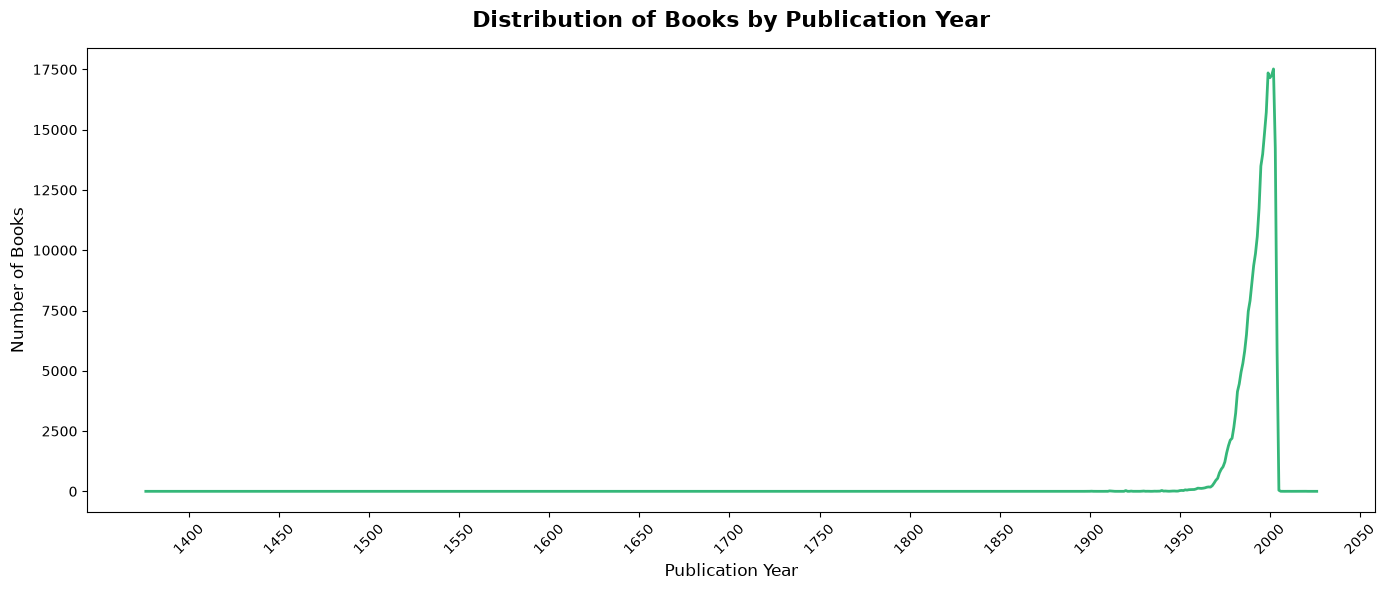

In [147]:
year_counts = df_books['Year-Clean'].value_counts().sort_index()

plt.figure(figsize=(14, 6))

sns.lineplot(
    x=year_counts.index,
    y=year_counts.values,
    linewidth=2,
    color=sns.color_palette('viridis', n_colors=8)[5]
)

plt.title(
    'Distribution of Books by Publication Year',
    fontsize=16,
    fontweight='bold',
    pad=15
)
plt.xlabel('Publication Year', fontsize=12)
plt.ylabel('Number of Books', fontsize=12)
plt.xticks(range(1400, 2051, 50), rotation=45)
plt.tight_layout()
plt.show()

### Insights

- The distribution shows that the dataset contains books published across a wide range of years.
- The number of books increases noticeably from the mid-20th century onward.
- The highest concentration of books appears during the late 1990s and early 2000s, with the peak around 2000.
- The chart contains a few unusually old publication years, which stretch the x-axis and make the distribution of recent years harder to interpret.
- This suggests that the dataset is more heavily represented by books published in recent decades than by older publications.

## 2 .Distribution of Book Ratings(Bar Plot)

C:\Users\CHIRIKI MANOJ KUMAR\AppData\Local\Temp\ipykernel_24612\3115532232.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


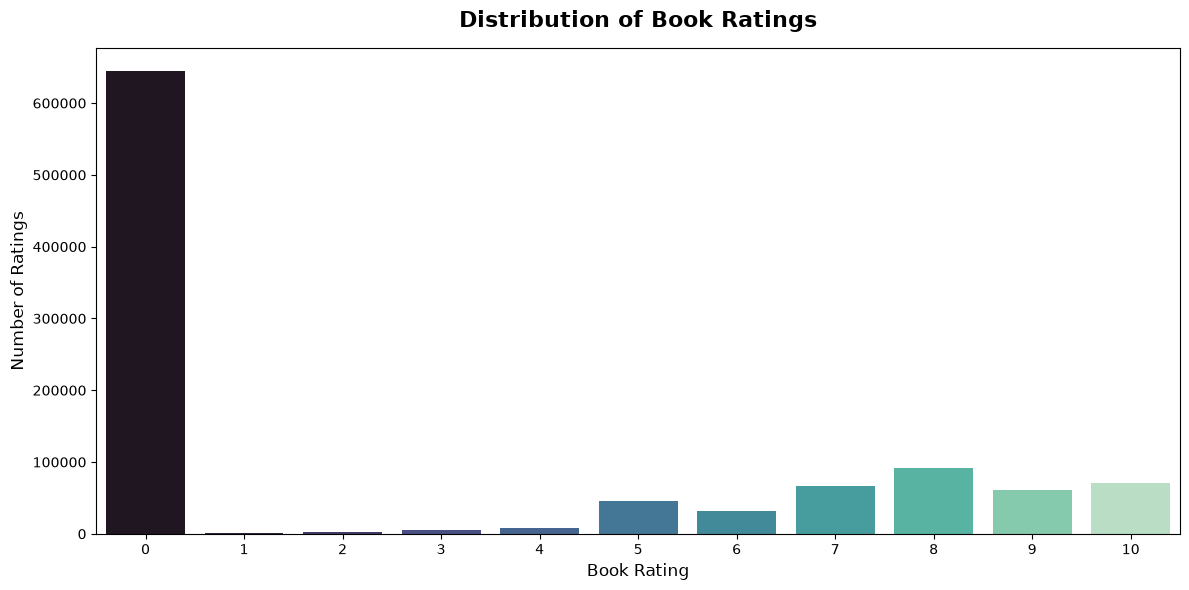

In [162]:
rating_counts = df_ratings_clean['Book-Rating'].value_counts().sort_index()

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values,
    palette=sns.color_palette('mako', n_colors=len(rating_counts))
)

plt.title(
    'Distribution of Book Ratings',
    fontsize=16,
    fontweight='bold',
    pad=15
)

plt.xlabel('Book Rating', fontsize=12)
plt.ylabel('Number of Ratings', fontsize=12)

plt.tight_layout()
plt.show()


### Insights
- Rating 0 has the highest frequency by a large margin, with approximately 630,000 ratings.
- Ratings from 1 to 4 occur very rarely compared with the other rating values.
- Among explicit ratings (1–10), rating 8 appears most frequently.
- Ratings 7, 8, 9, and 10 are more common than ratings 1–4, suggesting that users tend to give higher scores when they provide an explicit rating.
- The large number of zero ratings indicates that many records do not contain an explicit score.



## 3 .Top 10 Most Rated Books

C:\Users\CHIRIKI MANOJ KUMAR\AppData\Local\Temp\ipykernel_24612\3020628397.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


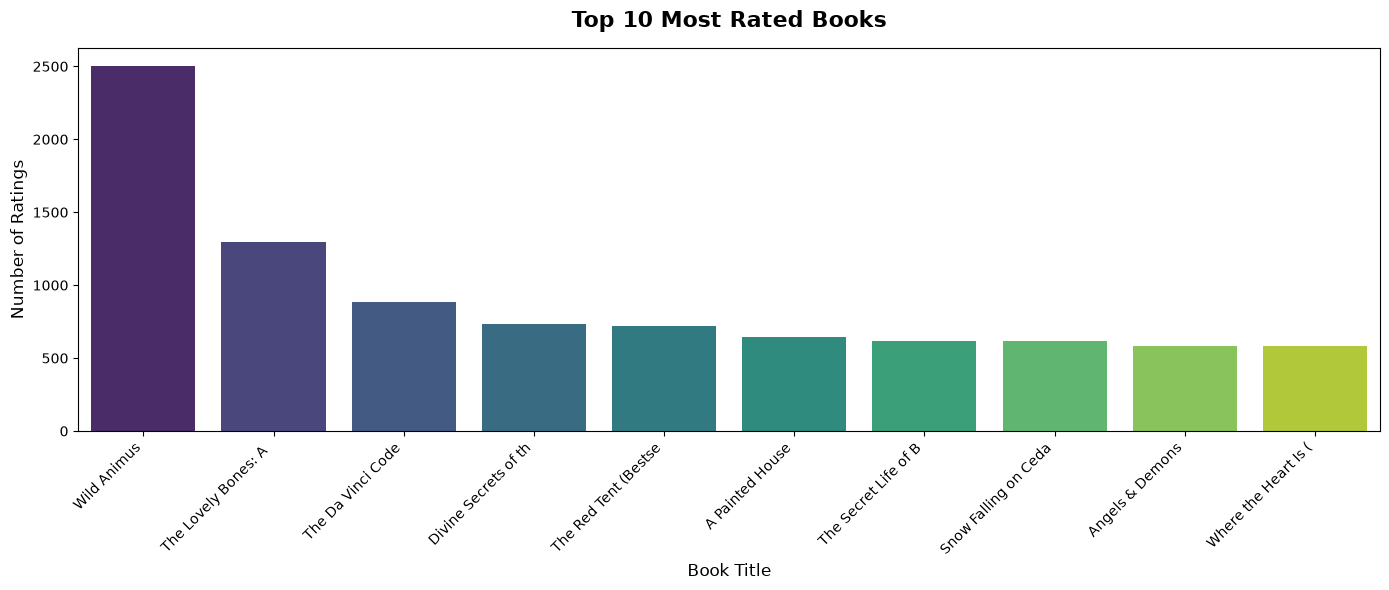

In [149]:
top_books = df_ratings_clean['ISBN'].value_counts().head(10)
book_titles = df_books.set_index('ISBN')['Book-Title']
top_book_titles = top_books.index.map(book_titles).str[:20]
plt.figure(figsize=(14, 6))
sns.barplot(
    x=top_book_titles,
    y=top_books.values,
    palette='viridis'
)
plt.title(
    'Top 10 Most Rated Books',
    fontsize=16,
    fontweight='bold',
    pad=15
)
plt.xlabel('Book Title', fontsize=12)
plt.ylabel('Number of Ratings', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Insights
- **Wild Animus** is the most-rated book, with approximately 2,500 ratings.
- **The Lovely Bones: A** is the second most-rated book, receiving approximately 1,300 ratings.
- **The Da Vinci Code** ranks third, with around 880 ratings.
- The remaining books each have approximately 570–720 ratings, showing a smaller difference in rating counts among them.
- Wild Animus has nearly twice as many ratings as The Lovely Bones: A, indicating a substantial gap between the top two books.
- These results show which books receive the most user ratings, but rating count alone does not indicate whether users liked the books.

## 4 ) Relationship Between Book Popularity and Average Rating

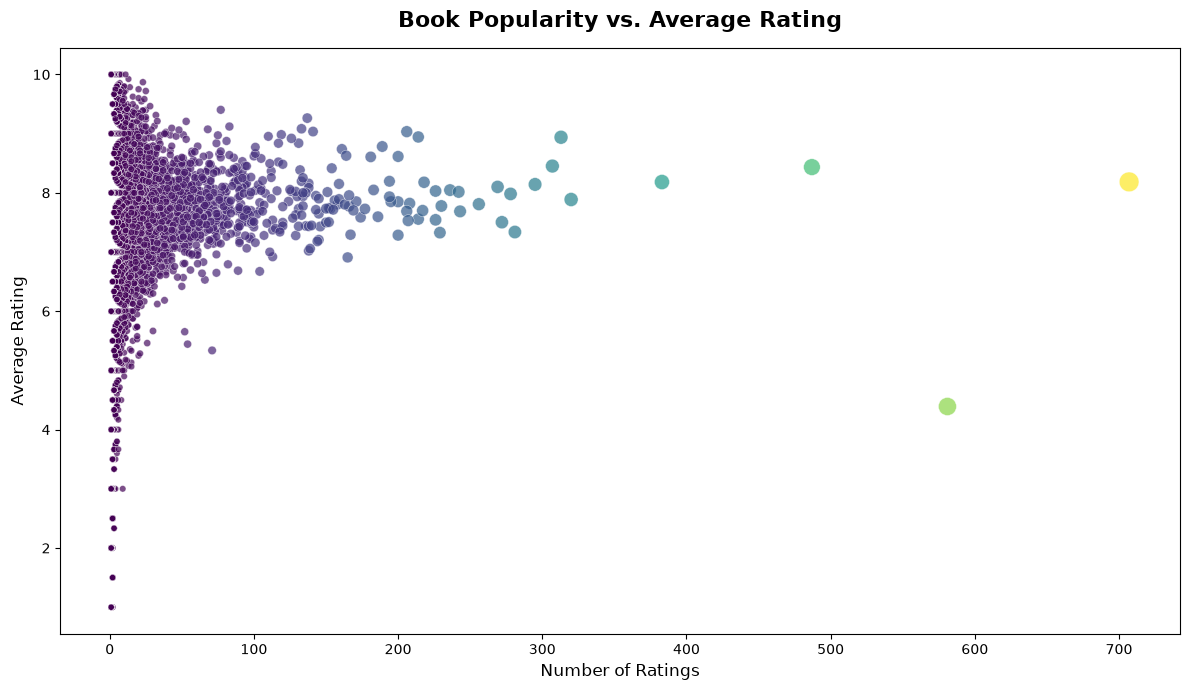

In [150]:
book_stats = (
    df_ratings_clean[df_ratings_clean['Book-Rating'] > 0]
    .groupby('ISBN')
    .agg(
        Number_of_Ratings=('Book-Rating', 'count'),
        Average_Rating=('Book-Rating', 'mean')
    )
    .reset_index()
)
plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=book_stats,
    x='Number_of_Ratings',
    y='Average_Rating',
    hue='Number_of_Ratings',
    palette='viridis',
    size='Number_of_Ratings',
    sizes=(20, 200),
    alpha=0.7,
    legend=False
)
plt.title(
    'Book Popularity vs. Average Rating',
    fontsize=16,
    fontweight='bold',
    pad=15
)
plt.xlabel('Number of Ratings', fontsize=12)
plt.ylabel('Average Rating', fontsize=12)
plt.tight_layout()
plt.show()

### Insights
- Most books have relatively few ratings, with the majority clustered below 100 ratings.
- Books with more ratings generally have average ratings concentrated around 7–8, suggesting that popular books tend to receive moderately high scores.
- The relationship between the number of ratings and average rating is not strongly linear; receiving more ratings does not automatically result in a higher average rating.
- A few highly rated-count books have average ratings above 8, while at least one popular book has an average rating around 4.4.
- Books with very few ratings show a wider range of average scores, from very low to very high values.
- The sparse points at high rating counts represent books with substantially greater popularity than most books in the dataset.

## 5 ) Distribution of Average Book Ratings

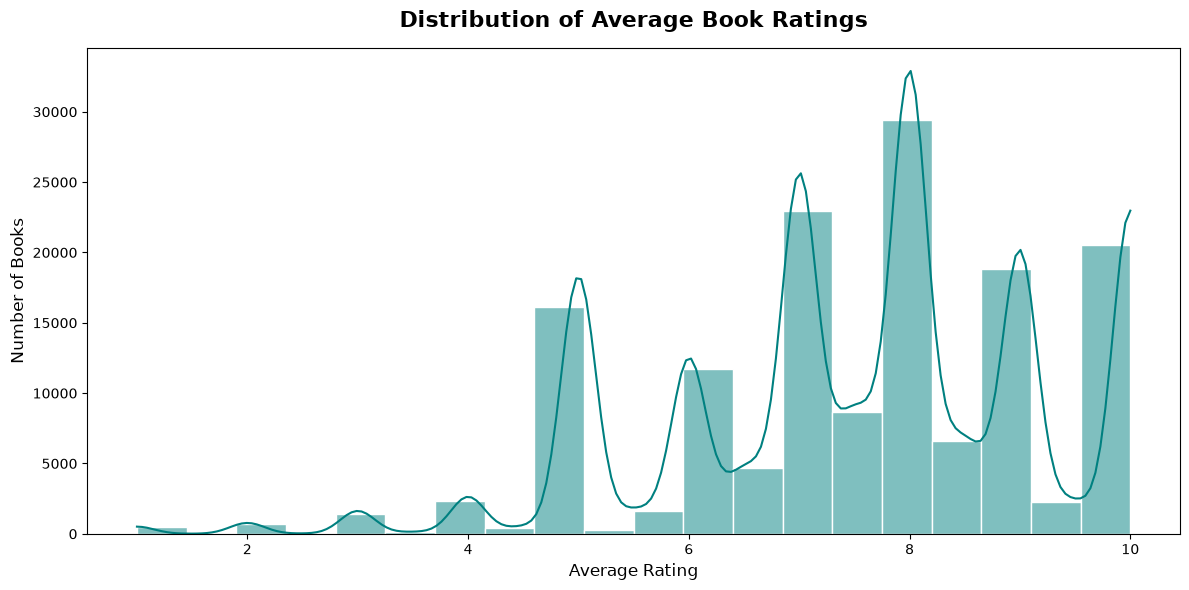

In [151]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=book_stats,
    x='Average_Rating',
    bins=20,
    kde=True,
    color='teal',
    edgecolor='white'
)

plt.title(
    'Distribution of Average Book Ratings',
    fontsize=16,
    fontweight='bold',
    pad=15
)

plt.xlabel('Average Rating', fontsize=12)
plt.ylabel('Number of Books', fontsize=12)

plt.tight_layout()
plt.show()

### Insights
- Average book ratings are concentrated toward the higher end of the scale, particularly between 7 and 10.
- The most prominent peak occurs around an average rating of 8, indicating that many books have an average score near this value.
- There are also noticeable peaks around ratings 5, 6, 7, 9, and 10, showing that the distribution is not smooth or uniform.
- Books with average ratings below 5 are relatively uncommon compared with books rated above 5.
- The distribution suggests that books in this dataset generally receive moderate-to-high average ratings.
- The histogram has several distinct peaks, which may reflect clustering around commonly occurring average-rating values.

## 6 ) Average Book Rating Across Popularity Groups

C:\Users\CHIRIKI MANOJ KUMAR\AppData\Local\Temp\ipykernel_24612\555442858.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


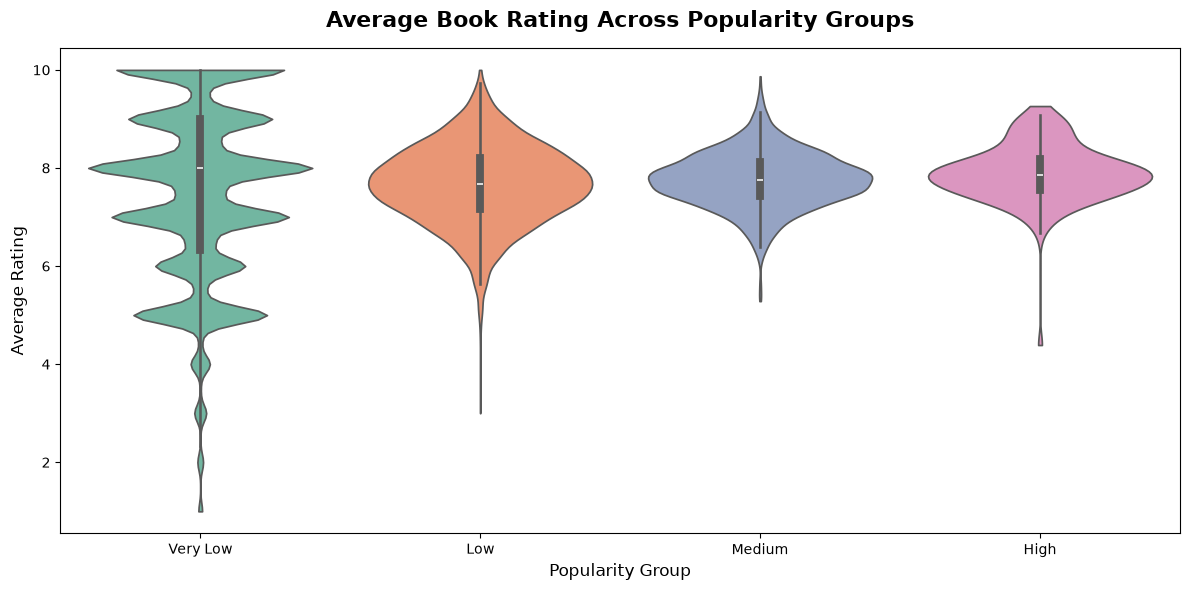

In [152]:
book_stats['Popularity_Group'] = pd.cut(
    book_stats['Number_of_Ratings'],
    bins=[0, 5, 20, 100, float('inf')],
    labels=['Very Low', 'Low', 'Medium', 'High']
)

plt.figure(figsize=(12, 6))

sns.violinplot(
    data=book_stats,
    x='Popularity_Group',
    y='Average_Rating',
    palette='Set2',
    inner='box',
    cut=0
)

plt.title(
    'Average Book Rating Across Popularity Groups',
    fontsize=16,
    fontweight='bold',
    pad=15
)

plt.xlabel('Popularity Group', fontsize=12)
plt.ylabel('Average Rating', fontsize=12)

plt.tight_layout()
plt.show()

### Insights
- The median average rating is close to 8 across all four popularity groups.
- The Very Low popularity group has the widest spread of average ratings, ranging from very low values to 10.
- The Low and Medium popularity groups have ratings concentrated mostly between 7 and 8, with fewer extreme values.
- The High popularity group has a relatively narrow distribution, with most average ratings clustered around 7.5–8.5.
- Books with very few ratings show greater variability in their average scores, while books with more ratings tend to have more consistent averages.
- The plot suggests that popularity does not necessarily correspond to a higher average rating; the groups have broadly similar central ratings.

## 7 ) Book Ratings Across User Age Groups

C:\Users\CHIRIKI MANOJ KUMAR\AppData\Local\Temp\ipykernel_24612\2232091034.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


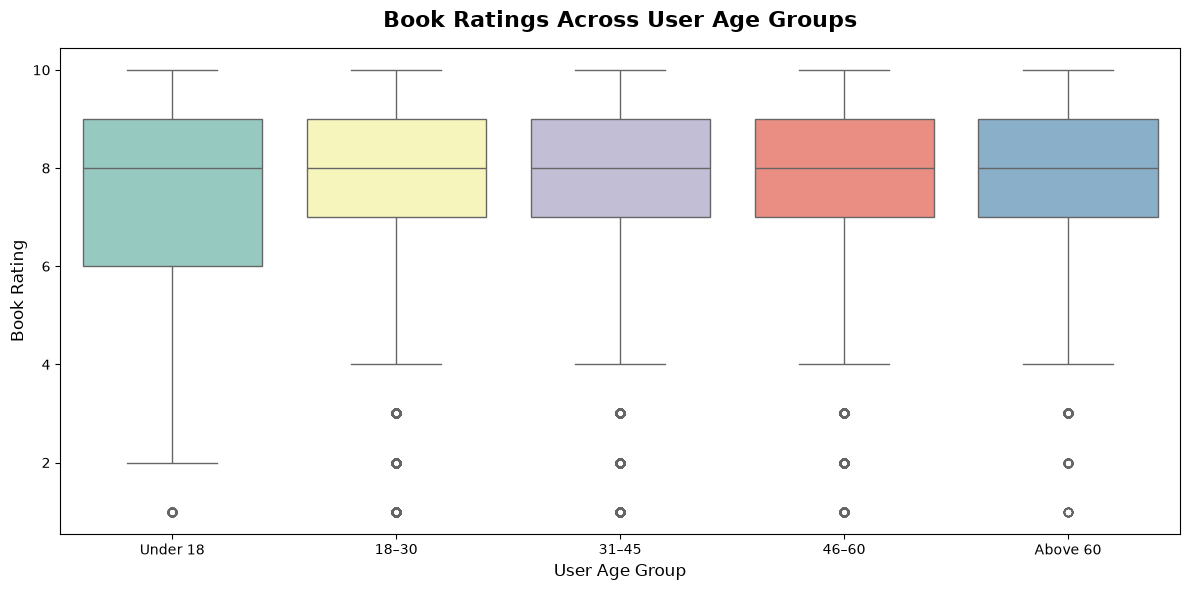

In [153]:
ratings_with_age = df_ratings_clean.merge(
    df_users[['User-ID', 'Age-Clean']],
    on='User-ID',
    how='inner'
)

ratings_with_age = ratings_with_age[
    (ratings_with_age['Book-Rating'] > 0) &
    (ratings_with_age['Age-Clean'].notna())
].copy()

ratings_with_age['Age_Group'] = pd.cut(
    ratings_with_age['Age-Clean'],
    bins=[0, 18, 30, 45, 60, float('inf')],
    labels=['Under 18', '18–30', '31–45', '46–60', 'Above 60']
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=ratings_with_age,
    x='Age_Group',
    y='Book-Rating',
    palette='Set3'
)

plt.title(
    'Book Ratings Across User Age Groups',
    fontsize=16,
    fontweight='bold',
    pad=15
)

plt.xlabel('User Age Group', fontsize=12)
plt.ylabel('Book Rating', fontsize=12)

plt.tight_layout()
plt.show()

### Insights
- The median rating is 8 across all five user age groups, indicating similar typical rating behavior among users of different ages.
- The middle 50% of ratings for most age groups lie between 7 and 9.
- Users under 18 show a wider spread of ratings, with the lower quartile at 6 compared with 7 for the other groups.
- Ratings of 1, 2, and 3 appear as low-rating outliers in the adult age groups.
- The overall rating distributions are quite similar across age groups, suggesting that user age does not show a strong difference in typical book ratings in this chart.

## 8 ) Relationship Between User Age and Rating Activity

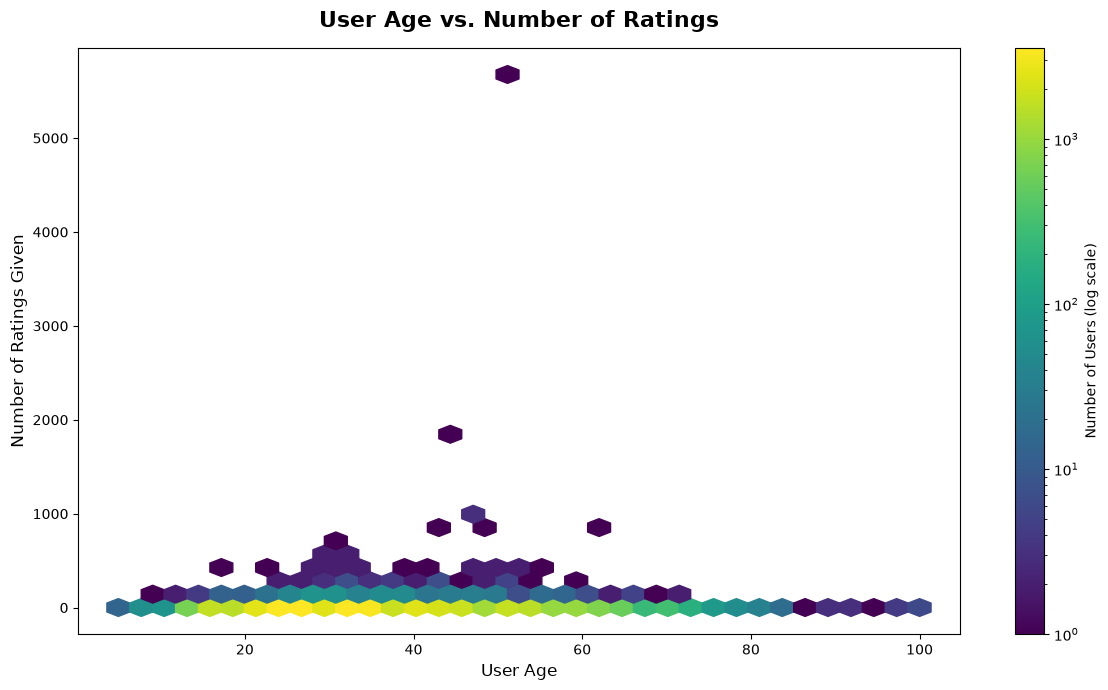

In [154]:
user_activity = (
    ratings_with_age
    .groupby('User-ID')
    .agg(
        Age=('Age-Clean', 'first'),
        Number_of_Ratings=('Book-Rating', 'count')
    )
    .reset_index()
)

plt.figure(figsize=(12, 7))

plt.hexbin(
    user_activity['Age'],
    user_activity['Number_of_Ratings'],
    gridsize=35,
    cmap='viridis',
    mincnt=1,
    bins='log'
)

plt.colorbar(label='Number of Users (log scale)')

plt.title(
    'User Age vs. Number of Ratings',
    fontsize=16,
    fontweight='bold',
    pad=15
)

plt.xlabel('User Age', fontsize=12)
plt.ylabel('Number of Ratings Given', fontsize=12)

plt.tight_layout()
plt.show()

### Insights
- The highest concentration of users appears in the younger-to-middle adult age range, particularly around ages 20–40.
- Most users give relatively few ratings, regardless of age, as the densest areas are concentrated near the bottom of the plot.
- A small number of users are highly active, giving hundreds or even thousands of ratings.
- The most extreme activity outliers appear around ages 45–55, including one user with more than 5,000 ratings.
- There is no clear linear relationship between user age and rating activity; high activity occurs at several ages rather than increasing steadily with age.
- The color gradient shows that many users are concentrated in the low-activity region, while high-activity users are comparatively rare.

## 9 ) Average Book Rating by User Age and Book Popularity

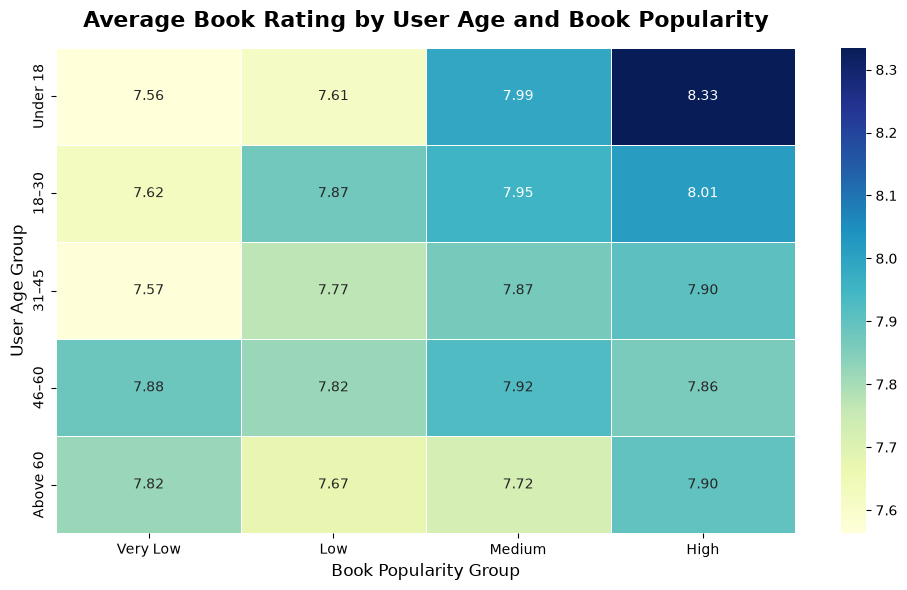

In [155]:
ratings_with_age['Popularity_Group'] = pd.cut(
    ratings_with_age.groupby('ISBN')['Book-Rating'].transform('count'),
    bins=[0, 5, 20, 100, float('inf')],
    labels=['Very Low', 'Low', 'Medium', 'High']
)

ratings_with_age['Age_Group'] = pd.cut(
    ratings_with_age['Age-Clean'],
    bins=[0, 18, 30, 45, 60, float('inf')],
    labels=['Under 18', '18–30', '31–45', '46–60', 'Above 60']
)

rating_heatmap_data = ratings_with_age.pivot_table(
    values='Book-Rating',
    index='Age_Group',
    columns='Popularity_Group',
    aggfunc='mean',
    observed=False
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    rating_heatmap_data,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu',
    linewidths=0.5
)

plt.title(
    'Average Book Rating by User Age and Book Popularity',
    fontsize=16,
    fontweight='bold',
    pad=15
)

plt.xlabel('Book Popularity Group', fontsize=12)
plt.ylabel('User Age Group', fontsize=12)

plt.tight_layout()
plt.show()

### Insights
- Average ratings are relatively consistent across all age and popularity groups, mostly ranging from 7.56 to 8.33.
- Users under 18 give the highest average rating to highly popular books, with an average of 8.33.
- Users aged 18–30 give their highest average rating to medium-popularity books (7.95), closely followed by highly popular books (8.01).
- Users aged 31–45 show a gradual increase in average rating as book popularity increases, from 7.57 for very low popularity to 7.90 for high popularity.
- Users aged 46–60 give their highest average rating to very low-popularity books (7.88), while ratings across the other popularity groups remain close.
- Users above 60 give their highest average rating to very low-popularity books (7.82) and their lowest to medium-popularity books (7.72).
- The heatmap shows no strong overall pattern linking book popularity to average rating; differences across groups are relatively small.

## 10 ) Publication Year, Book Popularity, and Average Rating

C:\Users\CHIRIKI MANOJ KUMAR\AppData\Local\Temp\ipykernel_24612\1392823087.py:41: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
c:\Users\CHIRIKI MANOJ KUMAR\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


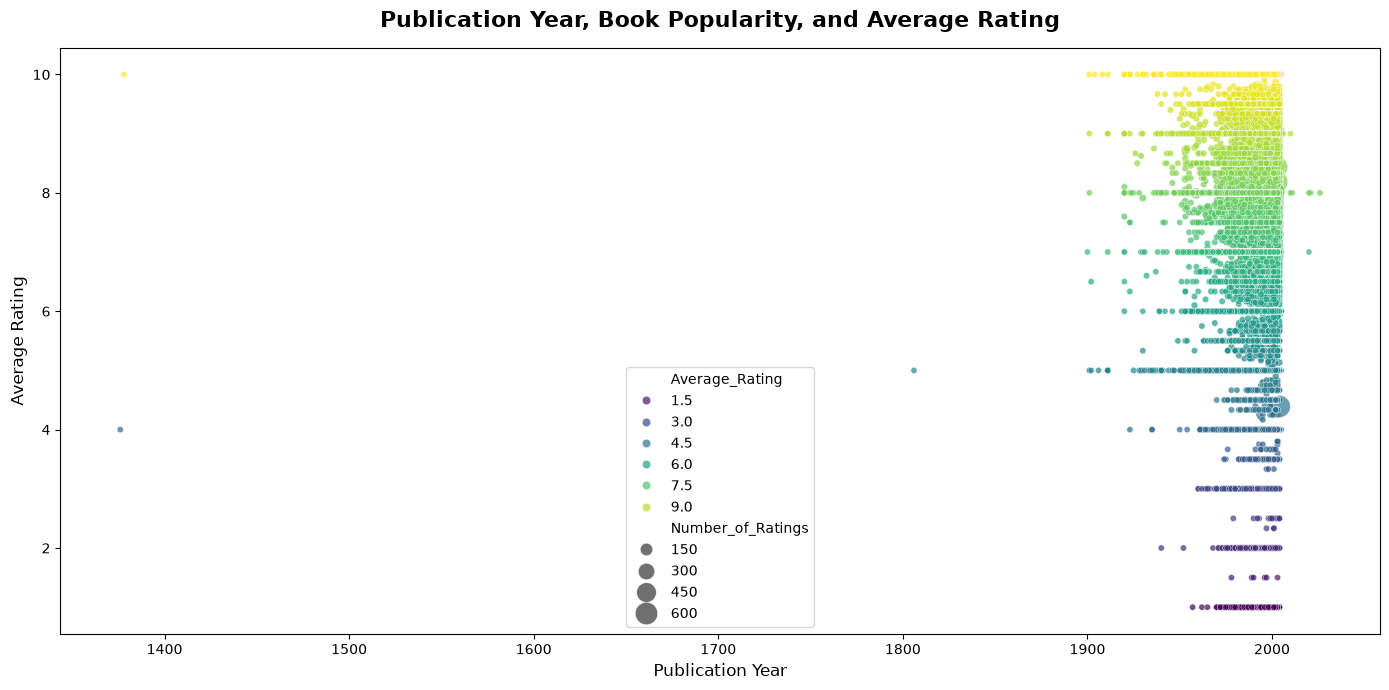

In [156]:
book_year_stats = (
    df_ratings_clean[df_ratings_clean['Book-Rating'] > 0]
    .groupby('ISBN')
    .agg(
        Number_of_Ratings=('Book-Rating', 'count'),
        Average_Rating=('Book-Rating', 'mean')
    )
    .reset_index()
    .merge(
        df_books[['ISBN', 'Year-Clean']],
        on='ISBN',
        how='left'
    )
    .dropna(subset=['Year-Clean'])
)

plt.figure(figsize=(14, 7))

sns.scatterplot(
    data=book_year_stats,
    x='Year-Clean',
    y='Average_Rating',
    size='Number_of_Ratings',
    hue='Average_Rating',
    sizes=(20, 300),
    palette='viridis',
    alpha=0.7,
    legend='brief'
)

plt.title(
    'Publication Year, Book Popularity, and Average Rating',
    fontsize=16,
    fontweight='bold',
    pad=15
)

plt.xlabel('Publication Year', fontsize=12)
plt.ylabel('Average Rating', fontsize=12)

plt.tight_layout()
plt.show()

### Insights
- Most books in the dataset were published between approximately 1990 and 2005, forming the densest cluster on the chart.
- Books published in recent decades show a wide range of average ratings, from low scores to ratings close to 10.
- Many books have average ratings between 7 and 9, indicating that high average scores are common across publication years.
- Larger bubbles represent books with more ratings. These popular books are mostly concentrated among publications from the late 20th century and early 21st century.
- The chart does not show a clear relationship between publication year and average rating; books from different years receive both high and low scores.
- A few very old publication years appear as outliers, including a point around 1376. These dates may need further data validation.

## 11 ) Book Ratings and Popularity Across Publication Decades

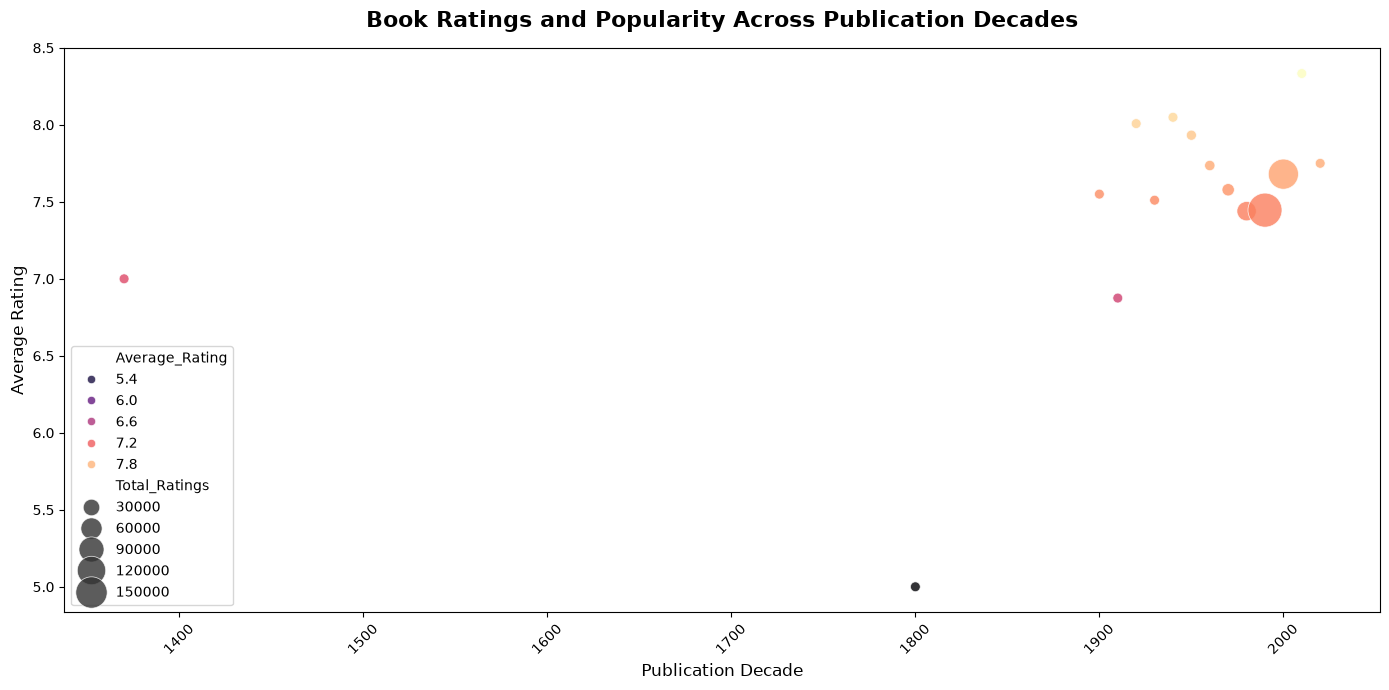

In [157]:
decade_stats = book_year_stats.copy()

decade_stats['Publication_Decade'] = (
    decade_stats['Year-Clean'] // 10 * 10
).astype(int)

decade_summary = (
    decade_stats
    .groupby('Publication_Decade')
    .agg(
        Average_Rating=('Average_Rating', 'mean'),
        Total_Ratings=('Number_of_Ratings', 'sum'),
        Number_of_Books=('ISBN', 'count')
    )
    .reset_index()
)

plt.figure(figsize=(14, 7))

sns.scatterplot(
    data=decade_summary,
    x='Publication_Decade',
    y='Average_Rating',
    size='Total_Ratings',
    hue='Average_Rating',
    sizes=(50, 600),
    palette='magma',
    alpha=0.8
)

plt.title(
    'Book Ratings and Popularity Across Publication Decades',
    fontsize=16,
    fontweight='bold',
    pad=15
)

plt.xlabel('Publication Decade', fontsize=12)
plt.ylabel('Average Rating', fontsize=12)

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Insights
- Most publication decades shown are concentrated between 1900 and 2020, with average ratings generally between 7.4 and 8.1.
- Books published in the 1990s and 2000s account for some of the largest bubbles, indicating a high total number of ratings for these decades.
- The 2000s decade has an average rating of approximately 7.7, while the 1990s decade is around 7.5.
- Some earlier decades, such as the 1920s and 1940s, show average ratings around 8.0, despite having smaller bubbles than the most popular recent decades.
- The 2010s decade has a notably high average rating of approximately 8.3, but its bubble is smaller than those of the 1990s and 2000s.
- The plot suggests that decades with more total ratings are not necessarily associated with higher average ratings.
- A few very old publication decades appear as outliers and should be interpreted cautiously because they may reflect unusual or inaccurate publication-year entries.

## 12 ) Distribution of User Ages

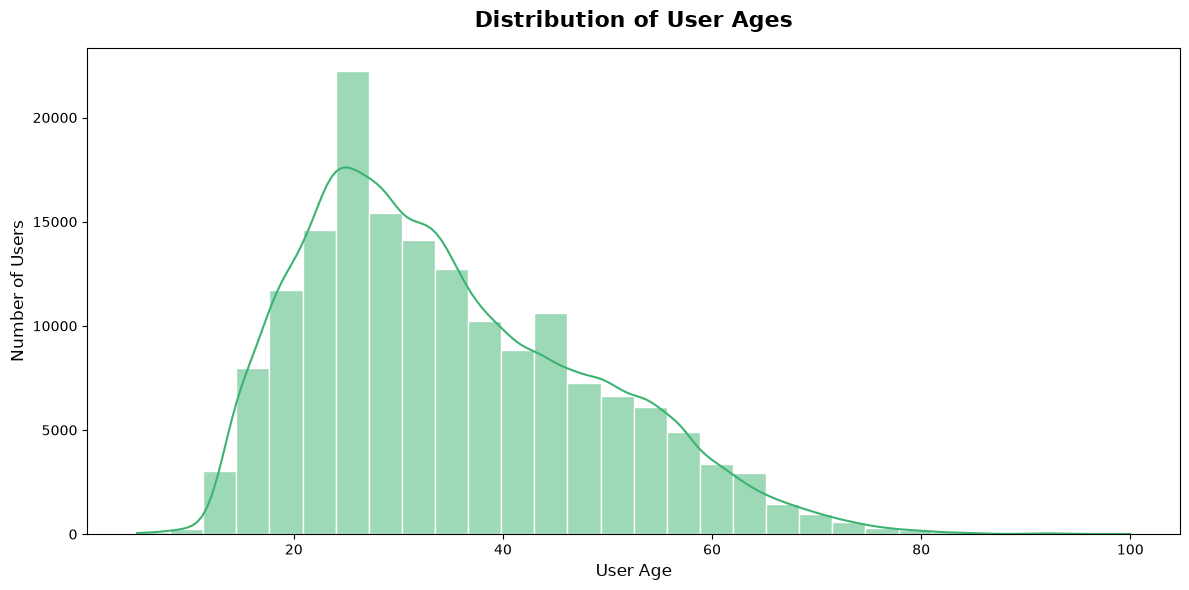

In [158]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df_users,
    x='Age-Clean',
    bins=30,
    kde=True,
    color='mediumseagreen',
    edgecolor='white'
)

plt.title(
    'Distribution of User Ages',
    fontsize=16,
    fontweight='bold',
    pad=15
)

plt.xlabel('User Age', fontsize=12)
plt.ylabel('Number of Users', fontsize=12)

plt.tight_layout()
plt.show()

### Insights
- The largest concentration of users falls within the age range of approximately 20–35 years.
- The highest bar appears around the mid-to-late 20s, indicating that users in this age range are the most represented in the dataset.
- The distribution is right-skewed: user counts decrease as age increases, with a long tail extending toward older ages.
- Users above 60 are much less represented than younger and middle-aged users.
- A small number of users are recorded at very high ages, extending close to 100.
- The age distribution is not symmetric, so the mean age may be higher than the median due to the long right tail.

## 13 ) Book Rating Distribution Across Popularity Groups

C:\Users\CHIRIKI MANOJ KUMAR\AppData\Local\Temp\ipykernel_24612\1205965341.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


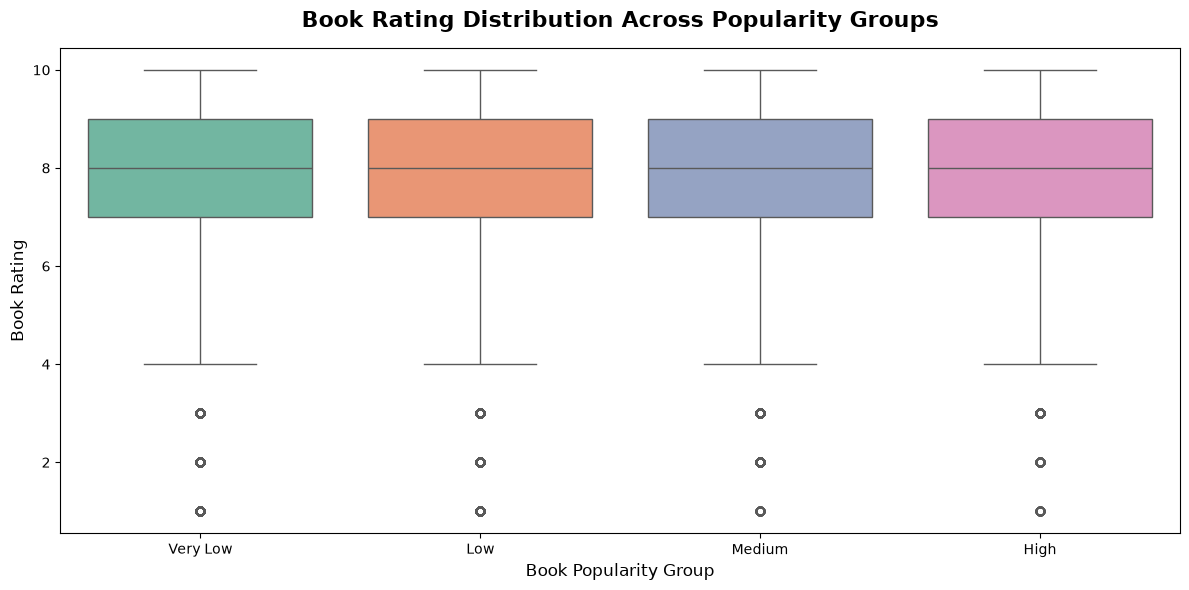

In [159]:
book_rating_groups = ratings_with_age.copy()

book_rating_groups['Popularity_Group'] = pd.cut(
    book_rating_groups.groupby('ISBN')['Book-Rating'].transform('count'),
    bins=[0, 5, 20, 100, float('inf')],
    labels=['Very Low', 'Low', 'Medium', 'High']
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=book_rating_groups,
    x='Popularity_Group',
    y='Book-Rating',
    palette='Set2'
)

plt.title(
    'Book Rating Distribution Across Popularity Groups',
    fontsize=16,
    fontweight='bold',
    pad=15
)

plt.xlabel('Book Popularity Group', fontsize=12)
plt.ylabel('Book Rating', fontsize=12)

plt.tight_layout()
plt.show()

### Insights
- The median rating is 8 across all four popularity groups, indicating that the typical rating is similar regardless of book popularity.
- The middle 50% of ratings range from 7 to 9 in every group, showing a consistent spread of ratings.
- The whiskers extend from approximately 4 to 10 for all groups, while ratings of 1, 2, and 3 appear as low-rating outliers.
- The four box plots have nearly identical shapes, suggesting that popularity group does not strongly change the distribution of individual ratings.
- Highly popular books do not show a higher median rating than books in the very low, low, or medium popularity groups.

## 14 ) Book Rating Patterns Across User Age Groups

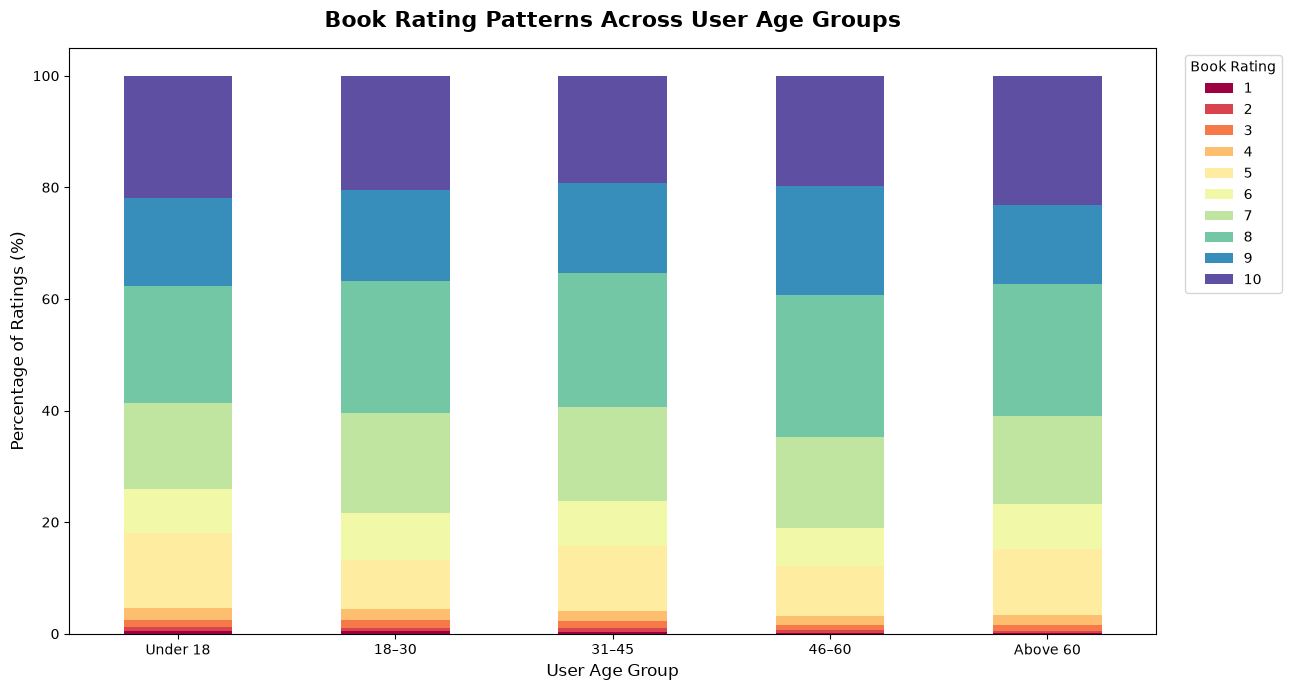

In [160]:
age_rating_counts = (
    ratings_with_age
    .groupby(['Age_Group', 'Book-Rating'], observed=False)
    .size()
    .reset_index(name='Number_of_Ratings')
)

age_rating_pivot = age_rating_counts.pivot(
    index='Age_Group',
    columns='Book-Rating',
    values='Number_of_Ratings'
).fillna(0)

age_rating_percent = age_rating_pivot.div(
    age_rating_pivot.sum(axis=1),
    axis=0
) * 100

age_rating_percent.plot(
    kind='bar',
    stacked=True,
    figsize=(13, 7),
    colormap='Spectral'
)

plt.title(
    'Book Rating Patterns Across User Age Groups',
    fontsize=16,
    fontweight='bold',
    pad=15
)

plt.xlabel('User Age Group', fontsize=12)
plt.ylabel('Percentage of Ratings (%)', fontsize=12)

plt.legend(
    title='Book Rating',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Insights
- Ratings of 7, 8, 9, and 10 make up the largest portions of ratings across all age groups.
- Rating 8 is one of the most common scores in every age group, while ratings of 1, 2, and 3 account for only a small percentage.
- Users aged 46–60 show a relatively larger share of ratings 7 and 8 compared with some other age groups.
- Users aged 18–30 and above 60 have a comparatively larger share of rating 10 than ratings 1–4.
- The overall composition of ratings is similar across age groups, with high scores dominating each stacked bar.
- Differences between age groups are present, but no age group shows a dramatically different rating pattern.

## 15 ) Average Book Rating and Popularity Across User Age Groups

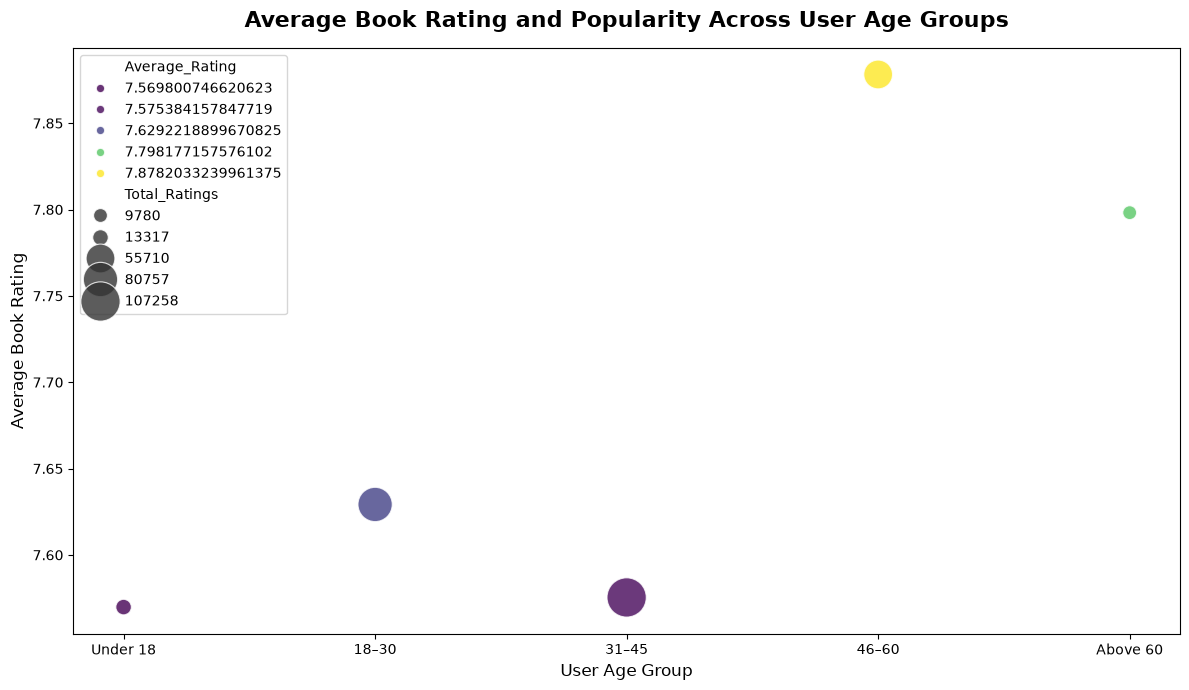

In [161]:
age_popularity_stats = (
    ratings_with_age[ratings_with_age['Book-Rating'] > 0]
    .groupby(['Age_Group', 'ISBN'])
    .agg(
        Average_Rating=('Book-Rating', 'mean'),
        Number_of_Ratings=('Book-Rating', 'count')
    )
    .reset_index()
)

age_popularity_summary = (
    age_popularity_stats
    .groupby('Age_Group')
    .agg(
        Average_Rating=('Average_Rating', 'mean'),
        Total_Ratings=('Number_of_Ratings', 'sum'),
        Number_of_Books=('ISBN', 'nunique')
    )
    .reset_index()
)

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=age_popularity_summary,
    x='Age_Group',
    y='Average_Rating',
    size='Total_Ratings',
    hue='Average_Rating',
    sizes=(100, 800),
    palette='viridis',
    alpha=0.8
)

plt.title(
    'Average Book Rating and Popularity Across User Age Groups',
    fontsize=16,
    fontweight='bold',
    pad=15
)

plt.xlabel('User Age Group', fontsize=12)
plt.ylabel('Average Book Rating', fontsize=12)

plt.tight_layout()
plt.show()

### Insights
- Users aged 46–60 have the highest average book rating, approximately 7.88.
- Users above 60 have the second-highest average rating, approximately 7.80.
- Users under 18 have the lowest average rating, approximately 7.57.
- The 31–45 age group contributes the largest number of ratings, represented by the largest bubble.
- Users aged 18–30 also contribute a substantial number of ratings, while the under-18 group contributes the fewest.
- Average ratings vary only modestly across age groups, remaining within approximately 7.57–7.88.

In [163]:
df_books.to_csv('Books_Cleaned.csv', index=False)
df_ratings_clean.to_csv('Ratings_Cleaned.csv', index=False)
df_users.to_csv('Users_Cleaned.csv', index=False)